# Gavish meta-programme activity in malignant breast epithelial cells

## Purpose

This notebook scores the 41 cancer meta-programmes (MPs) from Gavish et al. (2023) in the current malignant-cell subset. It deliberately distinguishes:

1. **comparable, fixed-control MP scores** for patient/sample summaries and condition-level descriptions;
2. **within-sample relative MP scores** for visualising intratumour heterogeneity; and
3. **provisional programme-dominant calls** with explicit activity, coherence, and top-versus-second-score requirements.

A Gavish MP is a transcriptional programme, **not an immutable cell identity**. The UMAP is used only to visualise scores and uncertainty; it does not define state boundaries or constitute a reference projection.

### Current, explicit temporary decisions

- The existing malignancy definition is retained unchanged.
- `patient` is temporarily an **analysis-level donor identifier** parsed from `sample`. Its condition prefix is retained intentionally, because raw identifier `MH0114` appears in both TN and ER+ samples. Source metadata must later resolve whether this is a true biological collision.
- All clinical summaries use one patient-level value per outcome. Cells and technical libraries are not treated as independent biological replicates.


In [1]:
import gc
import hashlib
import os
import re
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import seaborn as sns

from scipy.stats import kruskal

np.random.seed(0)
sc.settings.verbosity = 2
sns.set_theme(style="whitegrid", context="paper", palette="colorblind")


In [2]:
# ---------- User configuration ----------
# Set CAP_PROJECT before running on another machine.
project  = Path(os.environ.get("CAP_PROJECT", "/Volumes/TOSHIBA EXT/IdeaProjects/Nowotny")).expanduser()#4 Nina
data_dir = project / "Data"
save_dir = project / "Adata_Saves"
df_dir = project / "Dataframe_Saves"
fig_dir = project / "Figures"
for directory in [df_dir, fig_dir]: directory.mkdir(parents=True, exist_ok=True)

adata_file = save_dir / "epithelial_malignancy_scvi.h5ad"
gavish_file = data_dir / "Gavish_cell_state_signature.xlsx"

sample_key = "sample"
donor_key = "patient"                 # temporary analysis-level donor identifier
condition_key = "condition"
cluster_key = "epi_leiden"
expression_layer = "lognorm"

MIN_CELLS_PER_SAMPLE = 100
MIN_SIGNATURE_COVERAGE = 0.50
N_EXPRESSION_BINS = 25
N_CONTROLS_PER_SIGNATURE_GENE = 5
#N_NULL_SIGNATURES = 1000
N_NULL_SIGNATURES = 100#for exploration
NULL_QUANTILE = 0.99                  # MP-specific matched-gene null threshold
MIN_DETECTED_SIGNATURE_FRACTION = 0.20
TOP2_MARGIN = 0.25                    # report sensitivity analysis; do not optimise by condition
STRICT_DOUBLET_PERCENTILE = 0.90      # sensitivity analysis, not a biological filter
RANDOM_SEED = 0


## Load data and create a validated temporary analysis-level donor ID

The patch removes only terminal technical suffixes (`-T2`, `-T3`, `-Total`). It does **not** remove the subtype prefix. Thus `TN-MH0114` and `ER-MH0114` remain distinct while all HER2+ samples retain their specific identifier.


In [3]:
assert adata_file.exists(), adata_file
assert gavish_file.exists(), gavish_file

epi = sc.read_h5ad(adata_file)

required_obs = {sample_key, donor_key, condition_key, cluster_key, "malignant", "cnv_score", "cnv_signal", "doublet_score", "doublet_class"}
missing_obs = required_obs.difference(epi.obs.columns)
assert not missing_obs, f"Missing obs columns: {sorted(missing_obs)}"
assert expression_layer in epi.layers, f"Missing layer: {expression_layer}"
assert "X_umap" in epi.obsm, "Missing UMAP coordinates"

# TEMPORARY PATCH: retain the condition prefix, remove only known terminal suffixes.
sample_token = epi.obs[sample_key].astype(str).str.split("_", n=1).str[1]
epi.obs[donor_key] = sample_token.str.replace(r"(?:-T\d+|-Total)$", "", regex=True)

assert epi.obs[donor_key].notna().all()
assert epi.obs[donor_key].ne("").all()

sample_patient_check = (epi.obs[[sample_key, condition_key, donor_key]]
                        .drop_duplicates().sort_values([condition_key, donor_key, sample_key]))
print(sample_patient_check.to_string(index=False))
print("\nAnalysis-level donors per condition:")
print(sample_patient_check.groupby(condition_key, observed=True)[donor_key].nunique().sort_index())

cross_condition = sample_patient_check.groupby(donor_key, observed=True)[condition_key].nunique()
assert (cross_condition <= 1).all(), ("Temporary donor IDs span conditions:"
                                      f"{cross_condition[cross_condition > 1].index.tolist()}")
assert (sample_patient_check.loc[sample_patient_check[condition_key].eq("HER2+"), donor_key]
        .nunique() == 6), "Expected six HER2+ analysis-level donor IDs with the current dataset."


                   sample condition       patient
  GSM4909286_TN-B1-MH0131        TN  TN-B1-MH0131
  GSM4909288_TN-B1-MH0177        TN  TN-B1-MH0177
  GSM4909285_TN-B1-MH4031        TN  TN-B1-MH4031
 GSM4909287_TN-B1-Tum0554        TN TN-B1-Tum0554
  GSM4909284_TN-MH0114-T2        TN     TN-MH0114
     GSM4909281_TN-MH0126        TN     TN-MH0126
     GSM4909282_TN-MH0135        TN     TN-MH0135
     GSM4909283_TN-SH0106        TN     TN-SH0106
   GSM4909289_HER2-AH0308     HER2+   HER2-AH0308
   GSM4909291_HER2-MH0031     HER2+   HER2-MH0031
   GSM4909292_HER2-MH0069     HER2+   HER2-MH0069
   GSM4909293_HER2-MH0161     HER2+   HER2-MH0161
   GSM4909294_HER2-MH0176     HER2+   HER2-MH0176
   GSM4909290_HER2-PM0337     HER2+   HER2-PM0337
     GSM4909295_ER-AH0319       ER+     ER-AH0319
     GSM4909296_ER-MH0001       ER+     ER-MH0001
     GSM4909302_ER-MH0025       ER+     ER-MH0025
  GSM4909305_ER-MH0029-7C       ER+  ER-MH0029-7C
  GSM4909306_ER-MH0029-9C       ER+  ER-MH0029-9C


## Load, validate and document Gavish signatures

MPs with <50% coverage after the expression-data feature filtering are excluded from scoring. Coverage is saved and must be inspected, particularly for MP17 and MP18.


In [4]:
gavish_sheet = pd.read_excel(gavish_file, sheet_name="Cancer MPs")
gavish_sheet.columns = (gavish_sheet.columns.astype(str)
                        .str.replace(r"\s+", " ", regex=True).str.strip())

gavish_states = {}
mp_id_to_name = {}
for mp_name in gavish_sheet.columns:
    match = re.match(r"^(MP\d+)\b", mp_name)
    assert match is not None, f"Cannot parse MP identifier from {mp_name!r}"
    mp_id = match.group(1)
    genes = gavish_sheet[mp_name].dropna().astype(str).str.strip()
    genes = genes[genes.ne("")].unique().tolist()
    assert genes, f"Empty signature: {mp_name}"
    gavish_states[mp_name] = genes
    mp_id_to_name[mp_id] = mp_name

assert len(gavish_states) == 41, f"Expected 41 MPs, found {len(gavish_states)}"

coverage_rows = []
gavish_used = {}
for mp_name, genes in gavish_states.items():
    present = [gene for gene in genes if gene in epi.var_names]
    coverage = len(present) / len(genes)
    coverage_rows.append({
        "mp": mp_name,
        "n_signature_genes": len(genes),
        "n_present": len(present),
        "fraction_present": coverage,
        "used_for_scoring": coverage >= MIN_SIGNATURE_COVERAGE})
    if coverage >= MIN_SIGNATURE_COVERAGE:
        gavish_used[mp_name] = present

signature_coverage = pd.DataFrame(coverage_rows).sort_values("mp")
signature_coverage.to_csv(df_dir / "gavish_signature_coverage_revised.csv", index=False)
display(signature_coverage.round(3))
assert len(gavish_used) > 0, "No Gavish signatures passed coverage threshold."


,mp,n_signature_genes,n_present,fraction_present,used_for_scoring
0,MP1 Cell Cycle - G2/M,50,50,1.00,True
9,MP10 Protein maturation,50,50,1.00,True
10,MP11 Translation initiation,50,47,0.94,True
11,MP12 EMT-I,50,50,1.00,True
12,MP13 EMT-II,50,48,0.96,True
13,MP14 EMT-III,50,49,0.98,True
14,MP15 EMT IV,50,47,0.94,True
15,MP16 MES (glioma),50,49,0.98,True
16,MP17 Interferon/MHC-II (I),50,50,1.00,True
17,MP18 Interferon/MHC-II (II),50,48,0.96,True


## Build fixed matched controls and calculate comparable MP scores

The original notebook used `scanpy.tl.score_genes` separately in every technical sample. Its control genes can vary between samples, which complicates sample/patient comparison. Here, every MP receives one deterministic, expression-matched **fixed control set** selected from all retained malignant cells. The same signature and controls are then used for every scored cell.

The resulting `mp_score_fixed_control` is the primary score for patient-level summaries. It remains observational: batch and sample-quality diagnostics are required before any clinical inference.


In [5]:
# Keep the current malignancy definition unchanged, as agreed.
malignant_mask = epi.obs["malignant"].astype(bool).to_numpy()
malignant_obs = epi.obs.loc[malignant_mask, [sample_key, donor_key, condition_key, cluster_key]].copy()
X_malignant = epi.layers[expression_layer][malignant_mask].copy()

# Samples with too few malignant cells are not scored; record them explicitly.
sample_sizes = malignant_obs.groupby(sample_key, observed=True).size()
scored_samples = sample_sizes.index[sample_sizes >= MIN_CELLS_PER_SAMPLE]
scored_mask = malignant_obs[sample_key].isin(scored_samples).to_numpy()

scored_obs = malignant_obs.loc[scored_mask].copy()
X = X_malignant[scored_mask].copy()
scored_cells = scored_obs.index

skipped_samples = (sample_sizes[sample_sizes < MIN_CELLS_PER_SAMPLE].rename("n_malignant_cells")
                   .rename_axis(sample_key).reset_index())
skipped_samples.to_csv(df_dir / "gavish_skipped_small_samples_revised.csv", index=False)
print(f"Scored malignant cells: {X.shape[0]:,}")
print(f"Scored samples: {scored_obs[sample_key].nunique()}")
print(f"Scored analysis-level donors: {scored_obs[donor_key].nunique()}")
display(skipped_samples)

# Global mean expression defines expression-matched bins. These bins are only
# used to select controls/null genes; they are not used to normalise scores.
gene_names = pd.Index(epi.var_names.astype(str))
gene_mean = np.asarray(X.mean(axis=0)).ravel()
ranked_mean = pd.Series(gene_mean, index=gene_names).rank(method="first")
n_bins = min(N_EXPRESSION_BINS, len(gene_names))
gene_bin = pd.qcut(ranked_mean, q=n_bins, labels=False, duplicates="drop").astype(int)

all_signature_genes = set().union(*[set(genes) for genes in gavish_used.values()])
non_signature_genes = gene_names[~gene_names.isin(all_signature_genes)]
assert len(non_signature_genes) > 0, "No genes remain for matched control selection."
gene_to_position = pd.Series(np.arange(len(gene_names)), index=gene_names)

def stable_seed(text, base_seed=RANDOM_SEED):
    digest = hashlib.sha256(f"{base_seed}|{text}".encode()).hexdigest()
    return int(digest[:8], 16)

def matched_gene_set(signature_genes, rng, genes_allowed=non_signature_genes):
    """Select one non-signature gene for each signature gene from its expression bin.

    If a bin has no eligible gene, adjacent bins are searched. Sampling is with
    replacement because small bins can otherwise fail; duplicate genes are removed
    at the end. The function is deterministic conditional on `rng`.
    """
    selected = []
    allowed = pd.Index(genes_allowed)
    for gene in signature_genes:
        target_bin = int(gene_bin.loc[gene])
        candidates = allowed[gene_bin.loc[allowed].eq(target_bin).to_numpy()]
        if len(candidates) == 0:
            distances = (gene_bin.loc[allowed] - target_bin).abs()
            candidates = allowed[distances.eq(distances.min()).to_numpy()]
        selected.append(rng.choice(candidates))
    return pd.Index(selected).unique().tolist()

def fixed_controls(signature_genes, mp_name):
    """Create a fixed expression-matched control set for one MP."""
    rng = np.random.default_rng(stable_seed(f"controls::{mp_name}"))
    controls = []
    for _ in range(N_CONTROLS_PER_SIGNATURE_GENE):
        controls.extend(matched_gene_set(signature_genes, rng))
    controls = pd.Index(controls).unique().difference(pd.Index(signature_genes)).tolist()
    assert len(controls) >= 10, f"Too few matched controls for {mp_name}: {len(controls)}"
    return controls

def sparse_row_mean(matrix, column_positions):
    """Return row means for dense or sparse matrices without densifying all genes."""
    values = matrix[:, column_positions].mean(axis=1)
    return np.asarray(values).ravel()


Scored malignant cells: 89,377
Scored samples: 31
Scored analysis-level donors: 31


,sample,n_malignant_cells
0,GSM4909283_TN-SH0106,51


In [6]:
fixed_control_genes = {}
fixed_control_audit = []
mp_score_fixed_control = pd.DataFrame(index=scored_cells, dtype=float)
mp_detected_fraction = pd.DataFrame(index=scored_cells, dtype=float)

for mp_name, signature_genes in gavish_used.items():
    controls = fixed_controls(signature_genes, mp_name)
    fixed_control_genes[mp_name] = controls

    signature_positions = gene_to_position.loc[signature_genes].to_numpy()
    control_positions = gene_to_position.loc[controls].to_numpy()

    signature_mean = sparse_row_mean(X, signature_positions)
    control_mean = sparse_row_mean(X, control_positions)
    mp_score_fixed_control[mp_name] = signature_mean - control_mean

    detected = X[:, signature_positions] > 0
    mp_detected_fraction[mp_name] = np.asarray(detected.mean(axis=1)).ravel()

    fixed_control_audit.append({"mp": mp_name, "n_signature_genes_used": len(signature_genes), "n_fixed_controls": len(controls), "signature_genes": ";".join(signature_genes), "control_genes": ";".join(controls)})

assert mp_score_fixed_control.notna().all().all()
assert mp_detected_fraction.notna().all().all()
fixed_control_audit = pd.DataFrame(fixed_control_audit)
fixed_control_audit.to_csv(df_dir / "gavish_fixed_matched_controls.csv", index=False)
mp_score_fixed_control.to_csv(df_dir / "gavish_mp_fixed_control_scores.csv")
mp_detected_fraction.to_csv(df_dir / "gavish_mp_detected_fraction.csv")

display(fixed_control_audit[["mp", "n_signature_genes_used", "n_fixed_controls"]])


,mp,n_signature_genes_used,n_fixed_controls
0,MP1 Cell Cycle - G2/M,50,249
1,MP2 Cell Cycle - G1/S,49,243
2,MP3 Cell Cylce HMG-rich,47,213
3,MP4 Chromatin,49,237
4,MP5 Stress,50,237
5,MP6 Hypoxia,49,240
6,MP7 Stress (in vitro),49,234
7,MP8 Proteasomal degradation,50,238
8,MP9 Unfolded protein response,47,225
9,MP10 Protein maturation,50,234


## Programme-specific empirical null thresholds

For each MP, random gene sets matched to the MP's global mean-expression-bin profile are scored against the **same fixed controls**. Within each technical sample, the `NULL_QUANTILE` percentile of this matched null is the activity threshold. This controls for signature size and baseline gene expression, while avoiding a universal `z > 1` threshold.

This is a computational step. `N_NULL_SIGNATURES = 1000` is used for a stable null estimate; retain the same random seed for reproducibility and retain the same random seed.


In [7]:
def matched_null_thresholds_by_sample_fast(
        mp_name,
        signature_genes,
        control_genes,
        chunk_size=128,
):
    """Calculate matched-null thresholds using chunked sparse matrix products."""

    rng = np.random.default_rng(
        stable_seed(f"null::{mp_name}")
    )

    control_positions = gene_to_position.loc[control_genes].to_numpy()
    control_mean = sparse_row_mean(X, control_positions)

    n_cells = X.shape[0]
    n_genes = len(gene_names)

    null_scores = np.empty(
        (n_cells, N_NULL_SIGNATURES),
        dtype=np.float32,
    )

    for start in range(0, N_NULL_SIGNATURES, chunk_size):
        stop = min(start + chunk_size, N_NULL_SIGNATURES)
        n_chunk = stop - start

        membership_rows = []
        membership_cols = []
        membership_data = []

        for null_index in range(n_chunk):
            random_genes = matched_gene_set(
                signature_genes,
                rng,
            )
            random_positions = gene_to_position.loc[
                random_genes
            ].to_numpy()

            # Weight each selected gene so the product is a row-wise mean.
            weight = 1.0 / len(random_positions)

            membership_rows.extend(random_positions.tolist())
            membership_cols.extend([null_index] * len(random_positions))
            membership_data.extend(
                [weight] * len(random_positions)
            )

        signature_membership = sp.csc_matrix(
            (
                np.asarray(membership_data, dtype=np.float32),
                (
                    np.asarray(membership_rows, dtype=np.int32),
                    np.asarray(membership_cols, dtype=np.int32),
                ),
            ),
            shape=(n_genes, n_chunk),
        )

        random_signature_means = X @ signature_membership

        if sp.issparse(random_signature_means):
            random_signature_means = (
                random_signature_means.toarray()
            )
        else:
            random_signature_means = np.asarray(
                random_signature_means
            )

        null_scores[:, start:stop] = (
                random_signature_means
                - control_mean[:, None]
        ).astype(np.float32)

        print(
            f"{mp_name}: null signatures "
            f"{stop}/{N_NULL_SIGNATURES}",
            flush=True,
        )

    thresholds = {}

    for sample, cell_ids in scored_obs.groupby(
            sample_key,
            observed=True,
    ).groups.items():
        positions = scored_obs.index.get_indexer(cell_ids)

        thresholds[sample] = float(
            np.quantile(
                null_scores[positions, :],
                NULL_QUANTILE,
            )
        )

    return thresholds

In [8]:
null_threshold_rows = []
mp_activity = pd.DataFrame(index=scored_cells, dtype=bool)
for mp_name, signature_genes in gavish_used.items():
    thresholds = matched_null_thresholds_by_sample_fast(
        mp_name=mp_name,
        signature_genes=signature_genes,
        control_genes=fixed_control_genes[mp_name],
        chunk_size=128,
    )
    threshold_per_cell = scored_obs[sample_key].map(thresholds).astype(float)
    activity = (mp_score_fixed_control[mp_name].gt(threshold_per_cell)
                & mp_detected_fraction[mp_name].ge(MIN_DETECTED_SIGNATURE_FRACTION))
    mp_activity[mp_name] = activity

    for sample, threshold in thresholds.items():
        null_threshold_rows.append({
            "mp": mp_name, sample_key: sample, "null_quantile": NULL_QUANTILE, "n_null_signatures": N_NULL_SIGNATURES, "activity_threshold": threshold})

null_thresholds = pd.DataFrame(null_threshold_rows)
null_thresholds.to_csv(df_dir / "gavish_mp_matched_null_thresholds.csv", index=False)
mp_activity.to_csv(df_dir / "gavish_mp_activity_calls.csv")
assert mp_activity.notna().all().all()

MP1 Cell Cycle - G2/M: null signatures 100/100
MP2 Cell Cycle - G1/S: null signatures 100/100
MP3 Cell Cylce HMG-rich: null signatures 100/100
MP4 Chromatin: null signatures 100/100
MP5 Stress: null signatures 100/100
MP6 Hypoxia: null signatures 100/100
MP7 Stress (in vitro): null signatures 100/100
MP8 Proteasomal degradation: null signatures 100/100
MP9 Unfolded protein response: null signatures 100/100
MP10 Protein maturation: null signatures 100/100
MP11 Translation initiation: null signatures 100/100
MP12 EMT-I: null signatures 100/100
MP13 EMT-II: null signatures 100/100
MP14 EMT-III: null signatures 100/100
MP15 EMT IV: null signatures 100/100
MP16 MES (glioma): null signatures 100/100
MP17 Interferon/MHC-II (I): null signatures 100/100
MP18 Interferon/MHC-II (II): null signatures 100/100
MP19 Epithelial Senescence: null signatures 100/100
MP20 MYC: null signatures 100/100
MP21 Respiration: null signatures 100/100
MP22 Secreted I: null signatures 100/100
MP23 Secreted II: null 

## Relative within-sample scores for heterogeneity plots only

This transformation deliberately removes sample-wide programme amplitude. It is useful for a within-tumour UMAP or heatmap, but is **not** used for condition comparisons.


In [9]:
mp_score_within_sample_z = pd.DataFrame(index=scored_cells, columns=mp_score_fixed_control.columns, dtype=float)

for sample, cell_ids in scored_obs.groupby(sample_key, observed=True).groups.items():
    values = mp_score_fixed_control.loc[cell_ids]
    median = values.median(axis=0)
    mad = (values - median).abs().median(axis=0)
    scale = (1.4826 * mad).replace(0, np.nan)
    mp_score_within_sample_z.loc[cell_ids] = values.subtract(median, axis=1).divide(scale, axis=1)

# Constant MPs within a sample carry no relative information; represent as zero.
mp_score_within_sample_z = mp_score_within_sample_z.fillna(0.0)
mp_score_within_sample_z.to_csv(df_dir / "gavish_mp_within_sample_relative_zscores.csv")


## Class summaries and activity-consistent programme calls

Class scores are a **secondary summary**. MPs are first robustly scaled once across all scored malignant cells, then averaged within each Gavish class. There is no second per-sample class re-scaling.

For cell-level calls, the original all-MP class mean is retained as a continuous summary, but it is not used alone to decide whether a class is supported. The call-specific class score is the mean of the **active member MPs only**. This prevents a class from winning because of a modest average across several inactive MPs while having no active constituent MP.

A cell-level call is now defined as follows:

- `low_activity`: no candidate class contains an MP that passes the matched-null and detection criteria;
- a class is ranked using the mean global robust z-score of its active member MPs;
- if exactly one candidate class is active, it is called without a top-two ambiguity penalty;
- if multiple classes are active, the active-class winner must exceed the second active class by `TOP2_MARGIN`;
- otherwise the cell is `mixed_active_but_ambiguous`.

The original all-MP ranking is retained as a diagnostic. When its winner is inactive, this is recorded as `score_activity_discordance`; it is not treated as biological evidence against the best active class. The call remains a descriptive programme label, not a universal cell identity.


In [10]:
gavish_hallmarks = {
    "Cell Cycle": ["MP1", "MP2", "MP3", "MP4"],
    "Stress or Hypoxia": ["MP5", "MP6", "MP7"],
    "Protein Regulation": ["MP8", "MP9", "MP10", "MP11"],
    "Mesenchymal": ["MP12", "MP13", "MP14", "MP15", "MP16"],
    "Interferon and MHC II": ["MP17", "MP18"],
    "Senescence": ["MP19"],
    "Oncogenic": ["MP20"],
    "Respiration": ["MP21"],
    "Secreted": ["MP22", "MP23"],
    "Cilia": ["MP24"],
    "Neural Lineage": ["MP25", "MP26", "MP27", "MP28", "MP29"],
    "Other Lineage": ["MP30", "MP31", "MP32"],
    "Haematological Lineage": ["MP33", "MP34", "MP35", "MP36", "MP37"],
    "Unassigned": ["MP38", "MP39", "MP40", "MP41"]}
gavish_hallmarks = {hallmark: [mp_id_to_name[mp_id] for mp_id in mp_ids if mp_id in mp_id_to_name]
    for hallmark, mp_ids in gavish_hallmarks.items()}

candidate_hallmarks = [hallmark for hallmark in gavish_hallmarks if hallmark != "Unassigned"]

# One global robust scaling step permits MPs with different numerical ranges to
# contribute comparably to a class mean, without forcing every sample to centre at 0.
mp_global_median = mp_score_fixed_control.median(axis=0)
mp_global_mad = (mp_score_fixed_control - mp_global_median).abs().median(axis=0)
mp_score_global_z = mp_score_fixed_control.subtract(mp_global_median, axis=1).divide(
    (1.4826 * mp_global_mad).replace(0, np.nan), axis=1).fillna(0.0)

class_score = pd.DataFrame(index=scored_cells, dtype=float)
class_score_active_only = pd.DataFrame(index=scored_cells, dtype=float)
class_has_active_mp = pd.DataFrame(index=scored_cells, dtype=bool)

for hallmark in candidate_hallmarks:
    member_mps = [mp for mp in gavish_hallmarks[hallmark] if mp in mp_score_global_z.columns]
    assert member_mps, f"No scored MPs for class {hallmark}"

    # Continuous class summary: all member MPs, retained for donor/cluster summaries.
    class_score[hallmark] = mp_score_global_z[member_mps].mean(axis=1)

    # Activity-consistent call score: only active member MPs provide evidence.
    active_members = mp_activity[member_mps]
    class_has_active_mp[hallmark] = active_members.any(axis=1)
    class_score_active_only[hallmark] = mp_score_global_z[member_mps].where(active_members).mean(axis=1)

# Original all-MP ranking is retained for diagnostics only.
ordered_class_scores = np.sort(class_score.to_numpy(dtype=float), axis=1)
original_top_class = class_score.idxmax(axis=1)
original_top_score = ordered_class_scores[:, -1]
original_top_minus_second = ordered_class_scores[:, -1] - ordered_class_scores[:, -2]
original_column_positions = class_has_active_mp.columns.get_indexer(original_top_class)
original_winning_class_is_active = class_has_active_mp.to_numpy()[
    np.arange(len(class_has_active_mp)), original_column_positions]

# Rank only classes with at least one active MP. A cell with one active class has
# no active-class runner-up and is therefore not labelled ambiguous by this rule.
active_score_for_ranking = class_score_active_only.fillna(-np.inf)
activity_consistent_top_class = active_score_for_ranking.idxmax(axis=1)
activity_consistent_top_score = active_score_for_ranking.max(axis=1).replace(-np.inf, np.nan)
active_ordered_scores = np.sort(active_score_for_ranking.to_numpy(dtype=float), axis=1)
n_active_classes = class_has_active_mp.sum(axis=1).astype(int)
has_any_active_class = n_active_classes.gt(0)

active_top_minus_second_for_rule = np.where(
    n_active_classes.ge(2),
    active_ordered_scores[:, -1] - active_ordered_scores[:, -2],
    np.inf,
)
# Store NaN rather than infinity for the one-active-class display value.
activity_consistent_top_minus_second = np.where(
    n_active_classes.ge(2), active_top_minus_second_for_rule, np.nan)

# Final cell-level label. The low-activity and active-but-ambiguous categories
# remain explicit rather than being hidden in one generic grey label.
programme_call = activity_consistent_top_class.astype(object)
programme_call = programme_call.where(has_any_active_class, "low_activity")
programme_call = programme_call.where(
    ~(has_any_active_class & (active_top_minus_second_for_rule < TOP2_MARGIN)),
    "mixed_active_but_ambiguous",
)

score_activity_discordance = has_any_active_class & ~original_winning_class_is_active

# `top_class`, `top_score`, and `top_minus_second` now refer to the
# activity-consistent call rule. Original all-MP values are stored separately.
cell_assignment = pd.DataFrame({
    "top_class": activity_consistent_top_class,
    "top_class_score": activity_consistent_top_score,
    "top_minus_second": activity_consistent_top_minus_second,
    "n_active_classes": n_active_classes,
    "winning_class_has_active_mp": has_any_active_class,
    "programme_call": programme_call,
    "original_top_class": original_top_class,
    "original_top_class_score": original_top_score,
    "original_top_minus_second": original_top_minus_second,
    "original_winning_class_has_active_mp": original_winning_class_is_active,
    "score_activity_discordance": score_activity_discordance,
}, index=scored_cells)

cell_assignment.to_csv(df_dir / "gavish_cell_programme_calls_revised.csv")
class_score.to_csv(df_dir / "gavish_class_scores_global_z.csv")
class_score_active_only.to_csv(df_dir / "gavish_class_scores_activity_consistent_global_z.csv")
class_has_active_mp.to_csv(df_dir / "gavish_class_has_active_mp.csv")

assert cell_assignment["programme_call"].notna().all()


/var/folders/kn/dz8n2v_j7cq3qn3h60y7qmwh0000gp/T/ipykernel_10054/771108291.py:64: RuntimeWarning: invalid value encountered in subtract
  active_ordered_scores[:, -1] - active_ordered_scores[:, -2],


In [11]:
# Add diagnostics that separate low activity, active ambiguity, and the
# original score/activity mismatch.
cell_assignment["n_active_mps"] = mp_activity.sum(axis=1).astype(int)
cell_assignment["n_active_classes"] = class_has_active_mp.sum(axis=1).astype(int)
cell_assignment["assignment_status"] = np.select(
    [
        cell_assignment["programme_call"].eq("low_activity"),
        cell_assignment["programme_call"].eq("mixed_active_but_ambiguous"),
    ],
    ["low_activity_all_classes", "mixed_active_but_ambiguous"],
    default="confident_call",
)

cell_assignment["best_active_class"] = activity_consistent_top_class
cell_assignment["best_active_class_score"] = activity_consistent_top_score
cell_assignment["original_best_class"] = original_top_class
cell_assignment["original_score_activity_discordance"] = score_activity_discordance

cell_assignment.to_csv(df_dir / "gavish_cell_programme_calls_revised.csv")

status_summary = (
    cell_assignment["assignment_status"]
    .value_counts(dropna=False)
    .rename_axis("assignment_status")
    .reset_index(name="n_cells")
    .assign(fraction=lambda x: x["n_cells"] / x["n_cells"].sum())
)
display(status_summary)

# This diagnostic quantifies how often the old all-member mean would have
# selected an inactive class despite the presence of active evidence elsewhere.
discordance_summary = (
    cell_assignment["score_activity_discordance"]
    .value_counts(dropna=False)
    .rename_axis("score_activity_discordance")
    .reset_index(name="n_cells")
    .assign(fraction=lambda x: x["n_cells"] / x["n_cells"].sum())
)
display(discordance_summary)


,assignment_status,n_cells,fraction
0,low_activity_all_classes,48168,0.538931
1,confident_call,38875,0.434955
2,mixed_active_but_ambiguous,2334,0.026114


,score_activity_discordance,n_cells,fraction
0,False,78446,0.877698
1,True,10931,0.122302


In [12]:
MARGIN_GRID = [0.00, 0.05, 0.10, 0.15, 0.20, 0.25]

margin_sensitivity = []
for margin in MARGIN_GRID:
    calls = activity_consistent_top_class.astype(object)
    calls = calls.where(has_any_active_class, "low_activity")
    calls = calls.where(
        ~(has_any_active_class & (active_top_minus_second_for_rule < margin)),
        "mixed_active_but_ambiguous",
    )

    summary = (
        calls.value_counts(dropna=False)
        .rename_axis("programme_call")
        .reset_index(name="n_cells")
    )
    summary["fraction_cells"] = summary["n_cells"] / len(calls)
    summary["top2_margin"] = margin
    margin_sensitivity.append(summary)

margin_sensitivity = pd.concat(margin_sensitivity, ignore_index=True)
margin_sensitivity.to_csv(
    df_dir / "gavish_assignment_margin_sensitivity.csv",
    index=False,
)

display(
    margin_sensitivity[
        margin_sensitivity["programme_call"].isin(
            ["low_activity", "mixed_active_but_ambiguous"])
    ].sort_values(["top2_margin", "programme_call"])
)


,programme_call,n_cells,fraction_cells,top2_margin
0,low_activity,48168,0.538931,0.00
14,low_activity,48168,0.538931,0.05
26,mixed_active_but_ambiguous,487,0.005449,0.05
29,low_activity,48168,0.538931,0.10
39,mixed_active_but_ambiguous,928,0.010383,0.10
44,low_activity,48168,0.538931,0.15
54,mixed_active_but_ambiguous,1394,0.015597,0.15
59,low_activity,48168,0.538931,0.20
68,mixed_active_but_ambiguous,1847,0.020665,0.20
74,low_activity,48168,0.538931,0.25


## Figure Settings

In [13]:
from matplotlib.colors import TwoSlopeNorm, to_hex
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Colourblind-aware colours, fixed across all discrete publication panels.
plot_categories = list(class_score.columns) + ["low_activity", "mixed_active_but_ambiguous", "no_consistent_enrichment"]
base_colours = sns.color_palette("tab20", n_colors=len(plot_categories))
programme_palette = dict(zip(plot_categories, map(to_hex, base_colours)))
programme_palette["low_activity"] = "#BDBDBD"
programme_palette["mixed_active_but_ambiguous"] = "#969696"
programme_palette["no_consistent_enrichment"] = "#D9D9D9"

# Cells that are not part of the scored malignant subset are background only.
background_colour = "#ECECEC"

# A cluster label requires at least two contributing donors. The consistency and
# separation thresholds are predeclared descriptive rules, not p-value cutoffs.
MIN_PATIENTS_PER_CLUSTER_FUNCTION = 2
MIN_POSITIVE_PATIENT_FRACTION = 0.50
CLUSTER_TOP2_MARGIN = 0.1

## IFN/MHC-II quality-control and doublet-sensitivity annotations

The IFN/MHC-II programme remains a valid tumour-cell hypothesis only if its cells are compatible with epithelial/tumour identity and not explained by immune/APC contamination or doublets. The following fields do not silently remove cells. They enable three prespecified sensitivity summaries: all cells, cells not called doublets by the current classifier, and cells below the sample-specific 90th percentile of the doublet score.


In [14]:
ifn_mps = [mp_id_to_name[mp_id] for mp_id in ["MP17", "MP18"] if mp_id in mp_id_to_name]
ifn_mps = [mp for mp in ifn_mps if mp in mp_activity.columns]
assert ifn_mps, "MP17/MP18 are unavailable after signature coverage filtering."

ifn_qc = scored_obs[[sample_key, donor_key, condition_key, cluster_key]].copy()
ifn_qc["IFN_MHCII_active_any_MP"] = mp_activity[ifn_mps].any(axis=1)
ifn_qc["IFN_MHCII_active_both_MPs"] = mp_activity[ifn_mps].all(axis=1)
ifn_qc["IFN_MHCII_class_dominant"] = cell_assignment["programme_call"].eq("Interferon and MHC II")

# Preserve the existing classifier result as the main doublet sensitivity label.
ifn_qc["existing_doublet_call"] = epi.obs.loc[scored_cells, "doublet_class"].astype(str)
ifn_qc["passes_existing_doublet_call"] = ~ifn_qc["existing_doublet_call"].str.contains("doublet", case=False, na=False)
ifn_qc["doublet_score"] = epi.obs.loc[scored_cells, "doublet_score"].astype(float)

sample_doublet_cutoff = ifn_qc.groupby(sample_key, observed=True)["doublet_score"].quantile(STRICT_DOUBLET_PERCENTILE)
ifn_qc["sample_doublet_percentile_cutoff"] = ifn_qc[sample_key].map(sample_doublet_cutoff)
ifn_qc["passes_strict_doublet_sensitivity"] = (ifn_qc["doublet_score"] < ifn_qc["sample_doublet_percentile_cutoff"])

# Add all available requested QC variables without requiring a specific schema beyond the current object.
for variable in ["cnv_score", "cnv_signal", "total_counts", "n_genes_by_counts", "pct_counts_mt"]:
    if variable in epi.obs:
        ifn_qc[variable] = epi.obs.loc[scored_cells, variable].to_numpy()

ifn_qc.to_csv(df_dir / "gavish_ifn_mhcii_qc_flags.csv")

ifn_patient_summary = (ifn_qc.groupby([donor_key, condition_key], observed=True)
    .agg(n_cells=(sample_key, "size"), n_samples=(sample_key, "nunique"), fraction_ifn_active_any=("IFN_MHCII_active_any_MP", "mean"), fraction_ifn_class_dominant=("IFN_MHCII_class_dominant", "mean"))
    .reset_index())
# Compute sensitivity fractions from the cell table to keep numerator and denominator explicit.
for label, mask in {
    "all_cells": pd.Series(True, index=ifn_qc.index),
    "existing_non_doublet": ifn_qc["passes_existing_doublet_call"],
    "strict_doublet_sensitivity": ifn_qc["passes_strict_doublet_sensitivity"],
}.items():
    subset = ifn_qc.loc[mask]
    summary = (subset.groupby([donor_key, condition_key], observed=True)["IFN_MHCII_active_any_MP"]
        .agg(["size", "mean"])
        .rename(columns={"size": f"n_{label}", "mean": f"fraction_ifn_{label}"}))
    ifn_patient_summary = ifn_patient_summary.merge(summary, left_on=[donor_key, condition_key], right_index=True, how="left")

ifn_patient_summary.to_csv(df_dir / "gavish_ifn_mhcii_patient_summary.csv", index=False)
display(ifn_patient_summary.sort_values([condition_key, donor_key]))


,patient,condition,n_cells,n_samples,fraction_ifn_active_any,fraction_ifn_class_dominant,n_all_cells,fraction_ifn_all_cells,n_existing_non_doublet,fraction_ifn_existing_non_doublet,n_strict_doublet_sensitivity,fraction_ifn_strict_doublet_sensitivity
24,TN-B1-MH0131,TN,4788,1,0.000000,0.000000,4788,0.000000,4788,0.000000,4309,0.000000
25,TN-B1-MH0177,TN,803,1,0.364882,0.062267,803,0.364882,803,0.364882,722,0.342105
26,TN-B1-MH4031,TN,3810,1,0.051444,0.017585,3810,0.051444,3810,0.051444,3429,0.051035
27,TN-B1-Tum0554,TN,2626,1,0.539223,0.204494,2626,0.539223,2626,0.539223,2363,0.517986
28,TN-MH0114,TN,146,1,0.335616,0.075342,146,0.335616,146,0.335616,131,0.282443
29,TN-MH0126,TN,966,1,0.563147,0.084886,966,0.563147,966,0.563147,869,0.537399
30,TN-MH0135,TN,4684,1,0.197481,0.001281,4684,0.197481,4684,0.197481,4215,0.196916
18,HER2-AH0308,HER2+,2646,1,0.030234,0.003401,2646,0.030234,2646,0.030234,2381,0.031499
19,HER2-MH0031,HER2+,1371,1,0.017505,0.013129,1371,0.017505,1371,0.017505,1233,0.012165
20,HER2-MH0069,HER2+,237,1,0.071730,0.025316,237,0.071730,237,0.071730,213,0.075117


## Patient-balanced cluster programme enrichment

Clusters are not automatically treated as cell identities. This section asks a narrower question: does a Leiden cluster show a reproducible programme-class deviation relative to the same donor's malignant-cell background?

For each cluster and analysis-level donor, class scores are averaged across cells. The donor-wide malignant-cell mean is subtracted so that donor-wide programme amplitude does not determine the result. A cluster receives a provisional `cluster_function_label` only when:

- at least `MIN_PATIENTS_PER_CLUSTER_FUNCTION` donors contribute cells;
- the leading class is positive in at least `MIN_POSITIVE_PATIENT_FRACTION` of contributing donors;
- the leading class exceeds the second class by at least `CLUSTER_TOP2_MARGIN`.

The label means **donor-consistent cluster enrichment**, not that every cell in the cluster has that state.


In [15]:
# Patient-centred class deviations: for every cluster/donor, compare the class
# score in that cluster with the donor's own average score across all scored malignant cells.
patient_overall_class = (
    class_score.join(scored_obs[[donor_key]])
    .groupby(donor_key, observed=True)
    .mean()
)

cluster_patient_class_scores = (
    class_score.join(scored_obs[[cluster_key, donor_key]])
    .groupby([cluster_key, donor_key], observed=True)
    .mean()
)

cluster_patient_deviation = cluster_patient_class_scores.copy()
for cluster, donor in cluster_patient_deviation.index:
    cluster_patient_deviation.loc[(cluster, donor)] = (
        cluster_patient_class_scores.loc[(cluster, donor)]
        - patient_overall_class.loc[donor]
    )

cluster_function_rows = []
for cluster, patient_values in cluster_patient_deviation.groupby(level=0, observed=True):
    patient_values = patient_values.droplevel(0)
    n_patients = patient_values.shape[0]

    mean_deviation = patient_values.mean(axis=0)
    fraction_positive = (patient_values > 0).mean(axis=0)
    ranking = mean_deviation.sort_values(ascending=False)
    top_function = ranking.index[0]
    second_function = ranking.index[1]
    top_minus_second = float(ranking.iloc[0] - ranking.iloc[1])

    has_support = n_patients >= MIN_PATIENTS_PER_CLUSTER_FUNCTION
    is_consistent = fraction_positive.loc[top_function] >= MIN_POSITIVE_PATIENT_FRACTION
    is_separated = top_minus_second >= CLUSTER_TOP2_MARGIN
    functional_label = (
        top_function
        if (has_support and is_consistent and is_separated)
        else "no_consistent_enrichment"
    )

    for hallmark in class_score.columns:
        cluster_function_rows.append({
            cluster_key: cluster,
            "hallmark": hallmark,
            "n_patients": n_patients,
            "mean_patient_centred_deviation": float(mean_deviation.loc[hallmark]),
            "fraction_patients_positive": float(fraction_positive.loc[hallmark]),
            "cluster_function_label": functional_label,
            "is_top_function": hallmark == top_function,
            "top_minus_second": top_minus_second,
            "passes_patient_support": has_support,
            "passes_consistency": bool(is_consistent),
            "passes_separation": is_separated,
        })

cluster_function_table = pd.DataFrame(cluster_function_rows)
cluster_function_labels = (
    cluster_function_table
    .drop_duplicates(cluster_key)
    .set_index(cluster_key)["cluster_function_label"]
)

# Reproducible staircase order: assigned state first, then descending enrichment,
# then cluster identifier. Unassigned clusters are kept at the end.
cluster_label_by_id = cluster_function_labels.astype(str)
cluster_strength_by_id = (
    cluster_function_table.loc[cluster_function_table["is_top_function"]]
    .set_index(cluster_key)["mean_patient_centred_deviation"]
)
state_order = [state for state in class_score.columns if state in set(cluster_label_by_id)]
state_order += ["no_consistent_enrichment"] if "no_consistent_enrichment" in set(cluster_label_by_id) else []
cluster_order_by_state = (
    pd.DataFrame({
        cluster_key: cluster_label_by_id.index,
        "assigned_state": cluster_label_by_id.values,
        "cluster_strength": cluster_label_by_id.index.map(cluster_strength_by_id),
    })
    .assign(
        state_rank=lambda x: x["assigned_state"].map({s: i for i, s in enumerate(state_order)}).fillna(len(state_order)),
        cluster_sort=lambda x: x[cluster_key].astype(str),
    )
    .sort_values(["state_rank", "cluster_strength", "cluster_sort"], ascending=[True, False, True])
)
cluster_order_by_state["cluster_label"] = cluster_order_by_state["assigned_state"]
cluster_order_by_state.to_csv(df_dir / "gavish_cluster_state_staircase_order.csv", index=False)

cluster_function_table.to_csv(df_dir / "gavish_cluster_functional_enrichment_revised.csv", index=False)
display(
    cluster_function_table.loc[cluster_function_table["is_top_function"]]
    .sort_values(["cluster_function_label", "mean_patient_centred_deviation"], ascending=[True, False])
    [[cluster_key, "hallmark", "cluster_function_label", "n_patients",
      "mean_patient_centred_deviation", "fraction_patients_positive",
      "top_minus_second", "passes_patient_support", "passes_consistency",
      "passes_separation"]]
)
hallmark_order = list(class_score.columns)

,epi_leiden,hallmark,cluster_function_label,n_patients,mean_patient_centred_deviation,fraction_patients_positive,top_minus_second,passes_patient_support,passes_consistency,passes_separation
52,4,Cell Cycle,Cell Cycle,30,2.797482,1.000000,2.171692,True,True,True
195,15,Cell Cycle,Cell Cycle,31,1.899722,1.000000,1.484317,True,True,True
87,6,Cilia,Cilia,4,13.439183,1.000000,11.947989,True,True,True
295,22,Cilia,Cilia,19,0.306456,0.736842,0.102483,True,True,True
69,5,Interferon and MHC II,Interferon and MHC II,29,1.704741,1.000000,1.419896,True,True,True
329,25,Interferon and MHC II,Interferon and MHC II,28,1.011039,0.928571,0.249086,True,True,True
250,19,Mesenchymal,Mesenchymal,28,2.629914,1.000000,1.128411,True,True,True
240,18,Oncogenic,Oncogenic,15,0.868703,0.866667,0.496167,True,True,True
37,2,Other Lineage,Other Lineage,12,0.485908,0.666667,0.192375,True,True,True
310,23,Other Lineage,Other Lineage,4,0.375965,0.750000,0.143305,True,True,True


## Patient-level programme summaries for clinical description

This section creates one patient-level value per MP/class. If a patient has multiple libraries, it first takes the median per library and then the median across that patient’s libraries. Do not perform cell-level condition tests.

No subtype p-values are produced automatically here because clinical inference requires a frozen patient-ID mapping and a prespecified covariate model. The exported table is the correct input for a later patient-level model or a robust patient-label permutation analysis.


## Cluster validation: composition, donor stability, and embedding/clustering sensitivity

The following checks evaluate whether a cluster-level programme label is more than a visual impression.

**A. Cluster composition:** quantify how many cells in each cluster have a confident call for the assigned cluster programme, how many are mixed, and how many have no detected Gavish activity. This distinguishes a broadly coherent cluster from a cluster whose mean is driven by a small subset.

**B. Leave-one-donor-out stability:** recompute the cluster label after removing each contributing donor. A label is considered leave-one-donor-out stable when the same label remains for every donor removal for which at least the minimum donor support remains.

**C. Clustering/embedding sensitivity:** the existing UMAP is a visualization, not an independent validation. The analysis therefore records sensitivity to alternative Leiden resolutions when a precomputed neighbor graph is available. It also reports cluster sizes and state-label frequencies across resolutions. These analyses do not claim that one resolution is biologically true.


In [16]:
# A. Composition of cell-level calls within each cluster and donor.
composition_frame = scored_obs[[cluster_key, donor_key, condition_key]].copy()
composition_frame["programme_call"] = cell_assignment.loc[scored_cells, "programme_call"].astype(str)
composition_frame["assignment_status"] = cell_assignment.loc[scored_cells, "assignment_status"].astype(str)
composition_frame["any_active_class"] = cell_assignment.loc[scored_cells, "n_active_classes"].gt(0).to_numpy()

cluster_state_lookup = cluster_function_labels.rename("assigned_state").to_frame()
composition_frame = composition_frame.join(cluster_state_lookup, on=cluster_key)

composition_rows = []
for (cluster, donor), frame in composition_frame.groupby([cluster_key, donor_key], observed=True):
    assigned_state = str(frame["assigned_state"].iloc[0])
    composition_rows.append({
        cluster_key: cluster,
        donor_key: donor,
        condition_key: str(frame[condition_key].iloc[0]),
        "assigned_state": assigned_state,
        "n_cells": len(frame),
        "fraction_assigned_state_call": float(frame["programme_call"].eq(assigned_state).mean()) if assigned_state in candidate_hallmarks else np.nan,
        "fraction_any_active_class": float(frame["any_active_class"].mean()),
        "fraction_confident_call": float(frame["assignment_status"].eq("confident_call").mean()),
        "fraction_mixed_active": float(frame["assignment_status"].eq("mixed_active_but_ambiguous").mean()),
        "fraction_no_gavish_activity": float(frame["assignment_status"].eq("low_activity_all_classes").mean()),
    })

cluster_donor_composition = pd.DataFrame(composition_rows)
cluster_donor_composition.to_csv(df_dir / "gavish_cluster_donor_cell_call_composition.csv", index=False)

cluster_composition_summary = (
    cluster_donor_composition
    .groupby([cluster_key, "assigned_state"], observed=True)
    .agg(
        n_donors=(donor_key, "nunique"),
        median_fraction_assigned_state_call=("fraction_assigned_state_call", "median"),
        median_fraction_confident_call=("fraction_confident_call", "median"),
        median_fraction_mixed_active=("fraction_mixed_active", "median"),
        median_fraction_no_gavish_activity=("fraction_no_gavish_activity", "median"),
        min_fraction_assigned_state_call=("fraction_assigned_state_call", "min"),
        max_fraction_assigned_state_call=("fraction_assigned_state_call", "max"),
    )
    .reset_index()
)
cluster_composition_summary.to_csv(df_dir / "gavish_cluster_cell_call_composition_summary.csv", index=False)
display(cluster_composition_summary.sort_values(["assigned_state", cluster_key]))


,epi_leiden,assigned_state,n_donors,median_fraction_assigned_state_call,median_fraction_confident_call,median_fraction_mixed_active,median_fraction_no_gavish_activity,min_fraction_assigned_state_call,max_fraction_assigned_state_call
7,15,Cell Cycle,31,0.505682,0.666667,0.000000,0.333333,0.00000,0.864924
20,4,Cell Cycle,30,0.748239,0.778081,0.000000,0.221919,0.13253,1.000000
15,22,Cilia,19,0.000000,0.363636,0.000000,0.636364,0.00000,0.000000
22,6,Cilia,4,1.000000,1.000000,0.000000,0.000000,0.50000,1.000000
18,25,Interferon and MHC II,28,0.020202,0.688172,0.000000,0.205962,0.00000,1.000000
21,5,Interferon and MHC II,29,0.500000,0.750000,0.052632,0.092308,0.00000,1.000000
11,19,Mesenchymal,28,0.629960,0.819396,0.044002,0.062568,0.00000,1.000000
10,18,Oncogenic,15,0.000000,0.625000,0.000000,0.250000,0.00000,0.500000
12,2,Other Lineage,12,0.000000,0.322446,0.000000,0.676527,0.00000,1.000000
16,23,Other Lineage,4,0.000000,0.049689,0.000000,0.950311,0.00000,0.000000


In [17]:
# B. Leave-one-donor-out stability of the cluster-level state labels.
# The same donor-centred scoring and decision thresholds are applied after each donor
# is removed; no threshold is optimized per donor or per condition.

def assign_cluster_functions_from_deviation(deviation_table):
    rows = []
    for cluster, values in deviation_table.groupby(level=0, observed=True):
        values = values.droplevel(0)
        n_patients = values.shape[0]
        mean_deviation = values.mean(axis=0)
        fraction_positive = (values > 0).mean(axis=0)
        ranking = mean_deviation.sort_values(ascending=False)
        top_function = ranking.index[0]
        top_minus_second = float(ranking.iloc[0] - ranking.iloc[1])
        label = (
            top_function
            if (
                n_patients >= MIN_PATIENTS_PER_CLUSTER_FUNCTION
                and fraction_positive.loc[top_function] >= MIN_POSITIVE_PATIENT_FRACTION
                and top_minus_second >= CLUSTER_TOP2_MARGIN
            )
            else "no_consistent_enrichment"
        )
        rows.append({
            cluster_key: cluster,
            "assigned_state_loo": label,
            "n_donors_loo": n_patients,
            "top_minus_second_loo": top_minus_second,
        })
    return pd.DataFrame(rows).set_index(cluster_key)

loo_rows = []
all_donors = sorted(scored_obs[donor_key].astype(str).unique())
for donor_to_leave_out in all_donors:
    keep = scored_obs[donor_key].astype(str).ne(donor_to_leave_out)
    loo_class = (
        class_score.loc[keep]
        .join(scored_obs.loc[keep, [cluster_key, donor_key]])
        .groupby([cluster_key, donor_key], observed=True)
        .mean()
    )
    loo_overall = (
        class_score.loc[keep]
        .join(scored_obs.loc[keep, [donor_key]])
        .groupby(donor_key, observed=True)
        .mean()
    )
    loo_deviation = loo_class.copy()
    for cluster, donor in loo_deviation.index:
        loo_deviation.loc[(cluster, donor)] = loo_class.loc[(cluster, donor)] - loo_overall.loc[donor]

    loo_labels = assign_cluster_functions_from_deviation(loo_deviation)
    for cluster, row in loo_labels.iterrows():
        original = str(cluster_function_labels.get(cluster, "no_consistent_enrichment"))
        loo_rows.append({
            "left_out_donor": donor_to_leave_out,
            cluster_key: cluster,
            "original_assigned_state": original,
            "assigned_state_loo": str(row["assigned_state_loo"]),
            "n_donors_loo": int(row["n_donors_loo"]),
            "top_minus_second_loo": float(row["top_minus_second_loo"]),
            "label_agrees": original == str(row["assigned_state_loo"]),
        })

cluster_loo_stability = pd.DataFrame(loo_rows)
cluster_loo_stability.to_csv(df_dir / "gavish_cluster_leave_one_donor_out_stability.csv", index=False)

cluster_loo_summary = (
    cluster_loo_stability
    .groupby([cluster_key, "original_assigned_state"], observed=True)
    .agg(
        n_leave_one_out_runs=("left_out_donor", "size"),
        n_agree=("label_agrees", "sum"),
        fraction_leave_one_out_agree=("label_agrees", "mean"),
        min_donors_remaining=("n_donors_loo", "min"),
        min_top_minus_second_loo=("top_minus_second_loo", "min"),
    )
    .reset_index()
)
cluster_loo_summary["leave_one_donor_out_stable"] = cluster_loo_summary["fraction_leave_one_out_agree"].eq(1.0)
cluster_loo_summary.to_csv(df_dir / "gavish_cluster_leave_one_donor_out_summary.csv", index=False)
display(cluster_loo_summary.sort_values(["leave_one_donor_out_stable", "fraction_leave_one_out_agree", cluster_key], ascending=[False, False, True]))


,epi_leiden,original_assigned_state,n_leave_one_out_runs,n_agree,fraction_leave_one_out_agree,min_donors_remaining,min_top_minus_second_loo,leave_one_donor_out_stable
0,0,Senescence,31,31,1.000000,22,0.154913,True
1,1,no_consistent_enrichment,31,31,1.000000,30,0.000461,True
3,11,Secreted,31,31,1.000000,28,0.122490,True
4,12,no_consistent_enrichment,30,30,1.000000,1,0.092932,True
5,13,no_consistent_enrichment,31,31,1.000000,29,0.021396,True
7,15,Cell Cycle,31,31,1.000000,30,1.415311,True
8,16,Respiration,31,31,1.000000,30,0.635221,True
9,17,no_consistent_enrichment,31,31,1.000000,28,0.000487,True
10,18,Oncogenic,31,31,1.000000,14,0.282665,True
11,19,Mesenchymal,31,31,1.000000,27,1.015187,True


In [18]:
# C. Sensitivity to Leiden resolution, using the existing neighbor graph when available.
# This is a clustering-sensitivity audit, not a claim that any resolution is correct.
LEIDEN_RESOLUTIONS = [0.4, 0.6, 0.8, 1.0, 1.2]
resolution_rows = []
resolution_labels = {}

if "neighbors" in epi.uns:
    sensitivity_adata = epi[scored_cells].copy()
    for resolution in LEIDEN_RESOLUTIONS:
        key = f"epi_leiden_sensitivity_{str(resolution).replace('.', '_')}"
        sc.tl.leiden(
            sensitivity_adata,
            resolution=resolution,
            key_added=key,
            directed=False,
            random_state=RANDOM_SEED,
        )
        resolution_labels[resolution] = sensitivity_adata.obs[key].astype(str).copy()
        counts = sensitivity_adata.obs[key].value_counts()
        for cluster_value, n_cells in counts.items():
            resolution_rows.append({
                "resolution": resolution,
                "cluster": str(cluster_value),
                "n_cells": int(n_cells),
            })
else:
    print("No neighbor graph found; Leiden-resolution sensitivity was not run.")

resolution_cluster_sizes = pd.DataFrame(resolution_rows)
resolution_cluster_sizes.to_csv(df_dir / "gavish_leiden_resolution_cluster_sizes.csv", index=False)

# Compare each resolution's clusters with the current epi_leiden labels using ARI.
from sklearn.metrics import adjusted_rand_score

resolution_ari_rows = []
if resolution_labels:
    reference_labels = scored_obs[cluster_key].astype(str)
    for resolution, labels in resolution_labels.items():
        resolution_ari_rows.append({
            "resolution": resolution,
            "adjusted_rand_index_vs_current": adjusted_rand_score(reference_labels, labels),
            "n_clusters": int(labels.nunique()),
        })
resolution_ari = pd.DataFrame(resolution_ari_rows)
resolution_ari.to_csv(df_dir / "gavish_leiden_resolution_sensitivity_ari.csv", index=False)
display(resolution_ari)
display(resolution_cluster_sizes.groupby("resolution", observed=True)["n_cells"].agg(["count", "min", "median", "max"]).reset_index() if not resolution_cluster_sizes.empty else resolution_cluster_sizes)


running Leiden clustering


/var/folders/kn/dz8n2v_j7cq3qn3h60y7qmwh0000gp/T/ipykernel_10054/2288272656.py:11: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(


    finished (0:02:20)
running Leiden clustering
    finished (0:01:34)
running Leiden clustering
    finished (0:04:23)
running Leiden clustering
    finished (0:02:33)
running Leiden clustering
    finished (0:03:38)


,resolution,adjusted_rand_index_vs_current,n_clusters
0,0.4,0.237218,14
1,0.6,0.456912,18
2,0.8,0.549375,20
3,1.0,0.557969,21
4,1.2,0.581467,23


,resolution,count,min,median,max
0,0.4,14,59,1511.5,50401
1,0.6,18,70,2661.0,20074
2,0.8,20,58,2756.5,13724
3,1.0,21,58,3050.0,12801
4,1.2,23,58,3308.0,9997


In [19]:
# First aggregate cells within each technical sample, then aggregate technical samples within donor.
sample_mp_summary = (mp_score_fixed_control.join(scored_obs[[sample_key, donor_key, condition_key]])
                     .groupby([sample_key, donor_key, condition_key], observed=True).median(numeric_only=True).reset_index())
patient_mp_summary = (sample_mp_summary
                      .groupby([donor_key, condition_key], observed=True)
                      .median(numeric_only=True)
                      .reset_index())

sample_class_summary = (class_score.join(scored_obs[[sample_key, donor_key, condition_key]])
                        .groupby([sample_key, donor_key, condition_key], observed=True)
                        .median(numeric_only=True).reset_index())
patient_class_summary = (sample_class_summary.groupby([donor_key, condition_key], observed=True)
                        .median(numeric_only=True).reset_index())

patient_mp_summary.to_csv(df_dir / "gavish_patient_level_mp_scores.csv", index=False)
patient_class_summary.to_csv(df_dir / "gavish_patient_level_class_scores.csv", index=False)

n_donors_by_condition = patient_mp_summary.groupby(condition_key, observed=True)[donor_key].nunique()
print("Analysis-level donors included in patient summaries:")
print(n_donors_by_condition.sort_index())
assert n_donors_by_condition.get("HER2+", 0) == 6, "HER2+ patient count unexpectedly changed."


Analysis-level donors included in patient summaries:
condition
TN        7
HER2+     6
ER+      18
Name: patient, dtype: int64


## Store all revised annotations in the AnnData object

Only scored malignant cells receive score/call values. Other cells are explicitly labelled `not_scored_or_non_malignant`; they are not included in programme summaries.


In [20]:
# Store score matrices with names that encode their intended interpretation.
# Important: activity calls are stored as float (1.0/0.0/NaN), rather than as
# pd.NA plus Boolean values. This avoids pandas attempting to insert Boolean
# objects into a string-typed column when this cell is rerun.
for mp_name in mp_score_fixed_control.columns:
    mp_id = re.match(r"^(MP\d+)\b", mp_name).group(1)

    fixed_score_column = f"Gavish_{mp_id}_fixed_control_score"
    epi.obs[fixed_score_column] = np.nan
    epi.obs.loc[scored_cells, fixed_score_column] = (
        mp_score_fixed_control.loc[scored_cells, mp_name].astype(float).to_numpy())

    within_sample_column = f"Gavish_{mp_id}_within_sample_z"
    epi.obs[within_sample_column] = np.nan
    epi.obs.loc[scored_cells, within_sample_column] = (
        mp_score_within_sample_z.loc[scored_cells, mp_name].astype(float).to_numpy())

    active_column = f"Gavish_{mp_id}_active"
    epi.obs[active_column] = np.nan
    epi.obs.loc[scored_cells, active_column] = (
        mp_activity.loc[scored_cells, mp_name].astype(float).to_numpy())

for hallmark in class_score.columns:
    class_column = f"Gavish_class_{hallmark}_global_z"
    epi.obs[class_column] = np.nan
    epi.obs.loc[scored_cells, class_column] = (
        class_score.loc[scored_cells, hallmark].astype(float).to_numpy())

for hallmark in class_score_active_only.columns:
    class_column = f"Gavish_call_class_{hallmark}_active_only_global_z"
    epi.obs[class_column] = np.nan
    epi.obs.loc[scored_cells, class_column] = (
        class_score_active_only.loc[scored_cells, hallmark].astype(float).to_numpy())

# Explicit object dtype allows string labels to be assigned safely, including
# when the cell has been run previously and the column was categorical.
call_column = "Gavish_programme_call_revised"
epi.obs[call_column] = pd.Series("not_scored_or_non_malignant", index=epi.obs_names, dtype="object",)
epi.obs.loc[scored_cells, call_column] = (
    cell_assignment.loc[scored_cells, "programme_call"].astype(str).to_numpy())
epi.obs[call_column] = epi.obs[call_column].astype("category")

status_column = "Gavish_assignment_status_revised"
epi.obs[status_column] = pd.Series("not_scored_or_non_malignant", index=epi.obs_names, dtype="object",)
epi.obs.loc[scored_cells, status_column] = (
    cell_assignment.loc[scored_cells, "assignment_status"].astype(str).to_numpy())
epi.obs[status_column] = epi.obs[status_column].astype("category")

epi.obs["Gavish_top_minus_second_revised"] = np.nan
epi.obs.loc[scored_cells, "Gavish_top_minus_second_revised"] = (
    cell_assignment.loc[scored_cells, "top_minus_second"].astype(float).to_numpy())
epi.obs["Gavish_original_top_minus_second_revised"] = np.nan
epi.obs.loc[scored_cells, "Gavish_original_top_minus_second_revised"] = (
    cell_assignment.loc[scored_cells, "original_top_minus_second"].astype(float).to_numpy())
epi.obs["Gavish_n_active_mps"] = np.nan
epi.obs.loc[scored_cells, "Gavish_n_active_mps"] = (
    cell_assignment.loc[scored_cells, "n_active_mps"].astype(float).to_numpy())
epi.obs["Gavish_n_active_classes"] = np.nan
epi.obs.loc[scored_cells, "Gavish_n_active_classes"] = (
    cell_assignment.loc[scored_cells, "n_active_classes"].astype(float).to_numpy())
epi.obs["Gavish_score_activity_discordance"] = np.nan
epi.obs.loc[scored_cells, "Gavish_score_activity_discordance"] = (
    cell_assignment.loc[scored_cells, "score_activity_discordance"].astype(float).to_numpy())

epi.obs["Gavish_IFN_MHCII_active_any_MP"] = np.nan
epi.obs.loc[scored_cells, "Gavish_IFN_MHCII_active_any_MP"] = (
    ifn_qc.loc[scored_cells, "IFN_MHCII_active_any_MP"].astype(float).to_numpy())

# Keep AnnData .uns H5AD-safe: strings, numbers, Booleans and nested mappings only.
epi.uns["gavish_assignment_revised"] = {
    "source": "Gavish et al. 2023 Cancer MPs",
    "primary_score": "fixed matched-control score on log-normalised expression",
    "relative_score": "within-sample robust z-score; visualisation only",
    "activity_rule": (
        f"score > {NULL_QUANTILE:.3f} matched-gene null quantile within sample "
        f"and >= {MIN_DETECTED_SIGNATURE_FRACTION:.2f} signature genes detected"),
    "programme_call_rule": (
        "rank classes by the mean global robust z-score of active member MPs; "
        f"one active class is accepted, while multiple active classes require "
        f"top-minus-second >= {TOP2_MARGIN:.2f}; no active class is low_activity"),
    "programme_call_labels": "programme class, low_activity, or mixed_active_but_ambiguous",
    "original_score_activity_discordance": "diagnostic only: old all-member-mean winner was inactive while another class had active MP evidence",
    "clinical_unit": "analysis-level donor ID; technical samples aggregated within donor",
    "umap_interpretation": "visual overlay only; not reference mapping and not a state-boundary estimator",
    "temporary_patient_patch": "condition-prefixed sample token with terminal -Tn/-Total suffix removed",
}

output_file = save_dir / "epithelial_malignancy_scvi_gavish_revised.h5ad"
epi.write_h5ad(output_file)
print(f"Saved revised AnnData: {output_file}")


/var/folders/kn/dz8n2v_j7cq3qn3h60y7qmwh0000gp/T/ipykernel_10054/1709676818.py:19: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  epi.obs[active_column] = np.nan
/var/folders/kn/dz8n2v_j7cq3qn3h60y7qmwh0000gp/T/ipykernel_10054/1709676818.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  epi.obs[fixed_score_column] = np.nan
/var/folders/kn/dz8n2v_j7cq3qn3h60y7qmwh0000gp/T/ipykernel_10054/1709676818.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which h

Saved revised AnnData: /Volumes/TOSHIBA EXT/IdeaProjects/Nowotny/Adata_Saves/epithelial_malignancy_scvi_gavish_revised.h5ad


## UMAP visualisation: continuous scores and uncertainty

These figures show continuous MP/class activity. They deliberately do not colour every cluster by one propagated state.


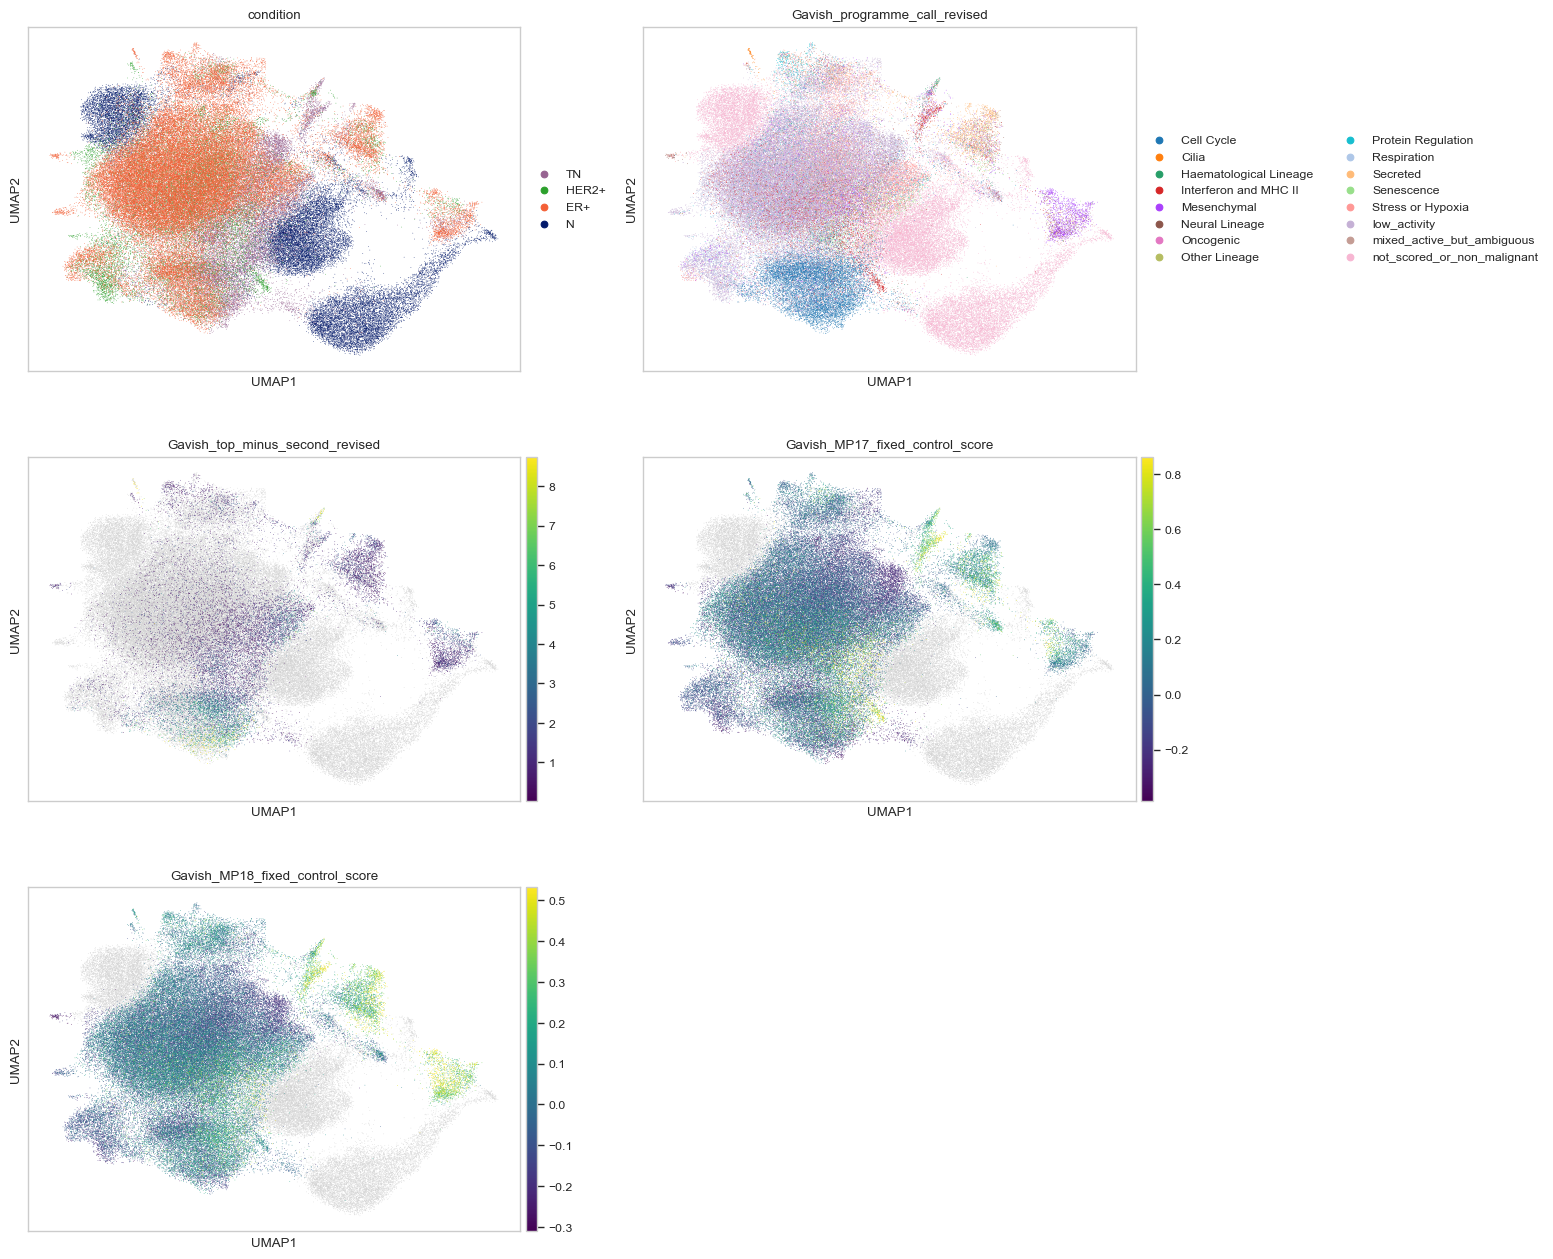

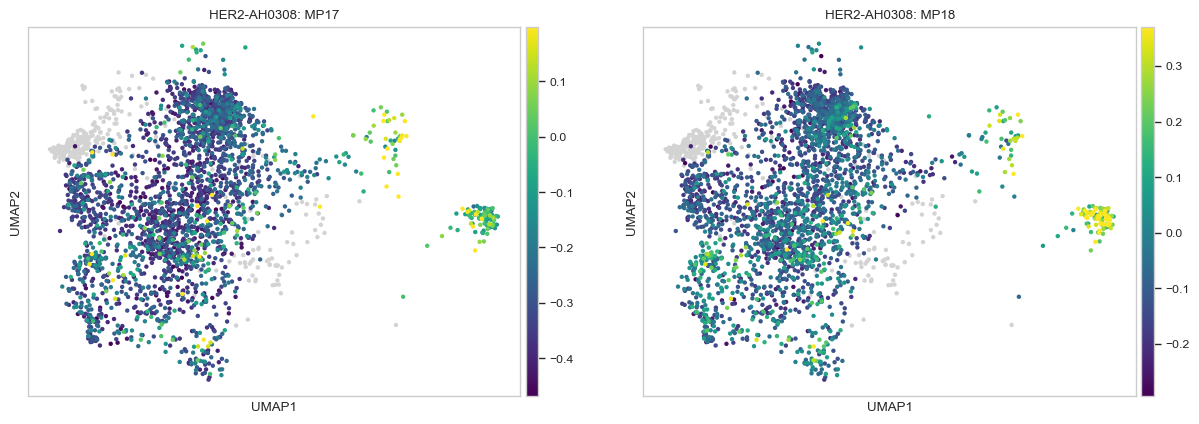

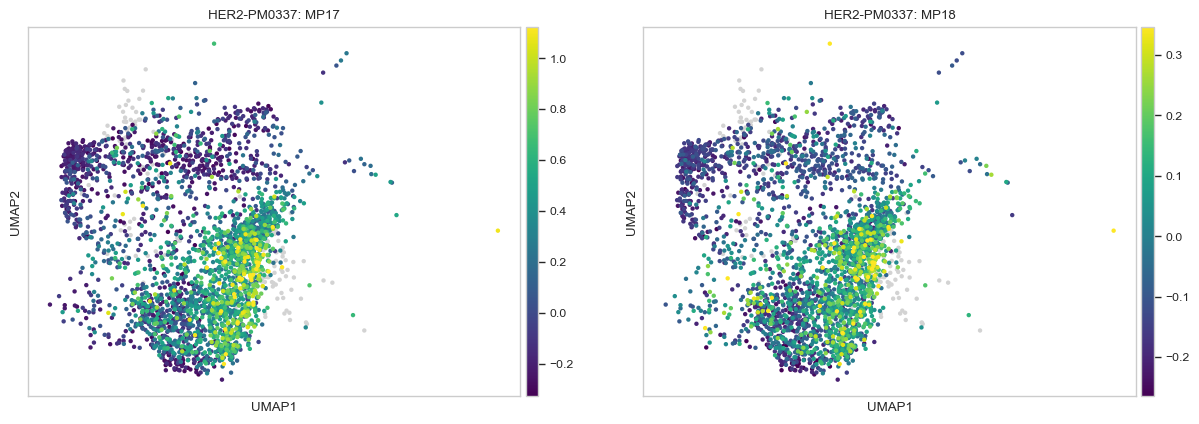

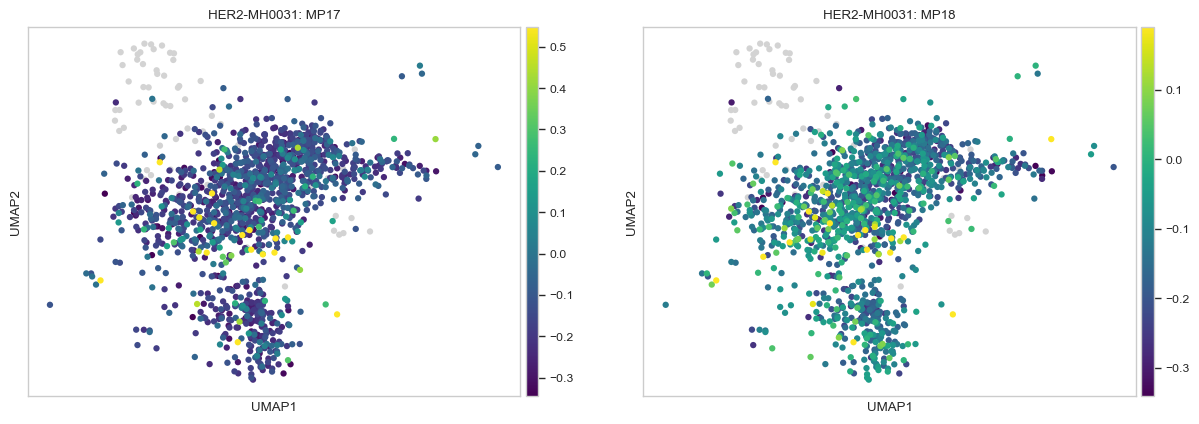

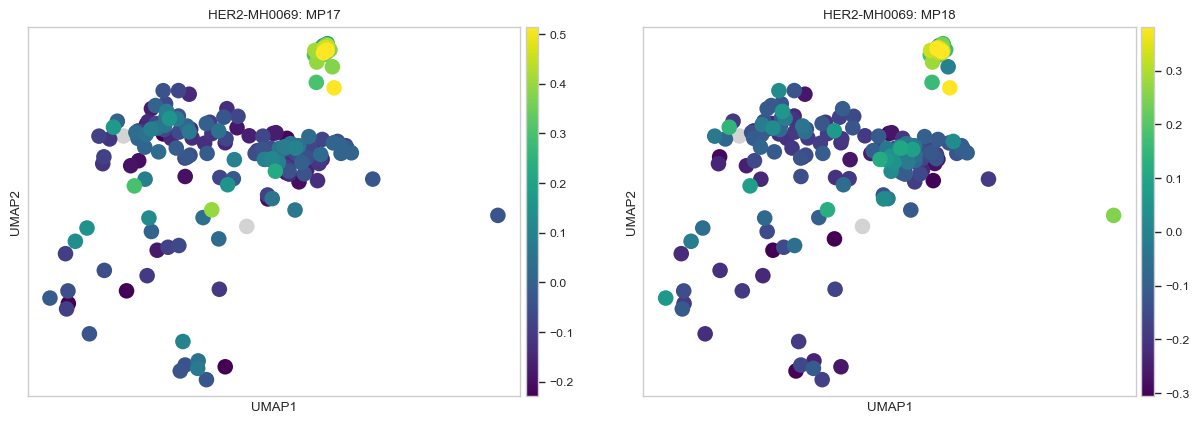

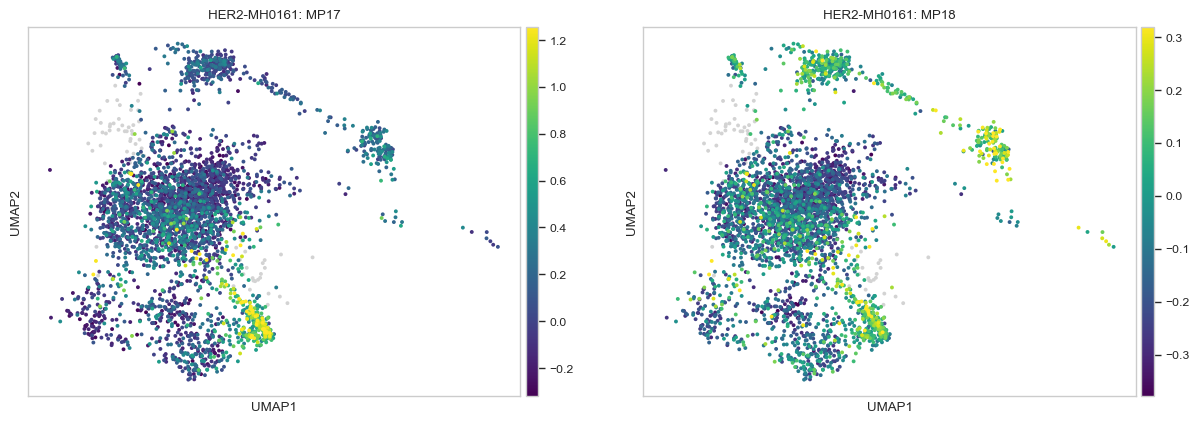

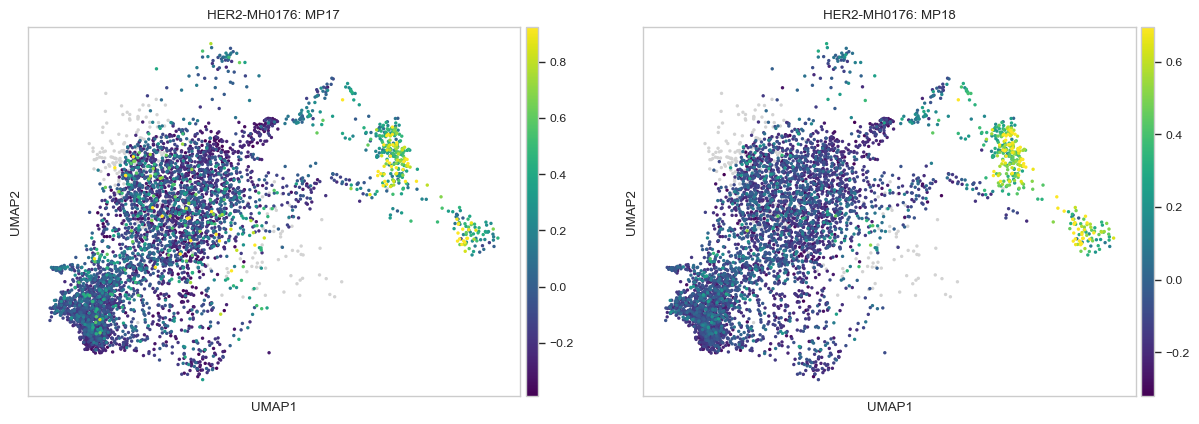

In [21]:
# MP17 and MP18 must be shown separately whenever available.
umap_features = ["condition", "Gavish_programme_call_revised", "Gavish_top_minus_second_revised"]
for mp_id in ["MP17", "MP18"]:
    column = f"Gavish_{mp_id}_fixed_control_score"
    if column in epi.obs:
        umap_features.append(column)

sc.pl.umap(epi,
    color=umap_features, ncols=2, use_raw=False, na_color="lightgrey", color_map="viridis", vmin="p01", vmax="p99", show=True)

# One panel per HER2+ donor for the two IFN/MHC-II MPs, if both are available.
her2_donors = scored_obs.loc[scored_obs[condition_key].eq("HER2+"), donor_key].drop_duplicates().tolist()
for donor in her2_donors:
    donor_cells = epi.obs[donor_key].eq(donor)
    sc.pl.umap(epi[donor_cells].copy(),
               color=[column for column in umap_features if "MP17" in column or "MP18" in column], ncols=2, use_raw=False, color_map="viridis", vmin="p01", vmax="p99", title=[f"{donor}: MP17", f"{donor}: MP18"][:len([c for c in umap_features if "MP17" in c or "MP18" in c])], show=True)


## IFN/MHC-II marker inspection

Inspect epithelial/tumour, IFN, MHC-II, and immune/APC markers before interpreting IFN/MHC-II activity as tumour-cell intrinsic. Absence from `var_names` is handled automatically.


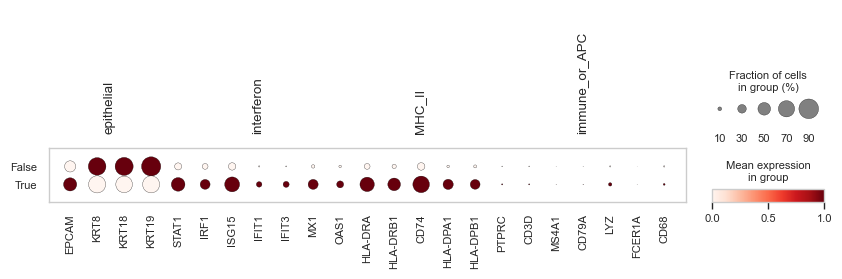

cnv_score  cnv_signal  doublet_score  \
condition IFN_MHCII_active_any_MP                                         
TN        False                     0.053009    0.233510       0.013469   
          True                      0.059016    0.248510       0.015733   
HER2+     False                     0.052440    0.292471       0.012459   
          True                      0.052635    0.284107       0.024865   
ER+       False                     0.050736    0.214917       0.017561   
          True                      0.049908    0.198845       0.015052   

                                   total_counts  n_genes_by_counts  \
condition IFN_MHCII_active_any_MP                                    
TN        False                          7604.5             1967.0   
          True                           5338.0             1938.0   
HER2+     False                          6502.0             2077.0   
          True                           8307.0             2363.0   
ER+       False                          3126.0             1187.0   
          True                           3497.0             1294.0   

                                   pct_counts_mt  
condition IFN_MHCII_active_any_MP                 
TN        False                         6.177208  
          True                          7.898010  
HER2+     False                         8.487574  
          True                          7.405884  
ER+       False                         5.929829  
          True                          5.157279

In [22]:
marker_groups = {
    "epithelial": ["EPCAM", "KRT8", "KRT18", "KRT19"],
    "interferon": ["STAT1", "IRF1", "ISG15", "IFIT1", "IFIT3", "MX1", "OAS1"],
    "MHC_II": ["HLA-DRA", "HLA-DRB1", "CD74", "HLA-DPA1", "HLA-DPB1"],
    "immune_or_APC": ["PTPRC", "CD3D", "MS4A1", "CD79A", "LYZ", "FCER1A", "CD68"]}
marker_groups = {
    group: [gene for gene in genes if gene in epi.var_names]
    for group, genes in marker_groups.items()}
marker_groups = {group: genes for group, genes in marker_groups.items() if genes}

plot_obs = epi[scored_cells].copy()
plot_obs.obs["IFN_MHCII_active_any_MP"] = ifn_qc["IFN_MHCII_active_any_MP"].astype(str).to_numpy()
sc.pl.dotplot(plot_obs, var_names=marker_groups, groupby="IFN_MHCII_active_any_MP", layer=expression_layer, standard_scale="var", show=True)

# Transparent QC comparison; this is descriptive, not a cell-level hypothesis test.
qc_columns = [column for column in ["cnv_score", "cnv_signal", "doublet_score", "total_counts", "n_genes_by_counts", "pct_counts_mt"] if column in ifn_qc]
ifn_qc_summary = (ifn_qc.groupby([condition_key, "IFN_MHCII_active_any_MP"], observed=True)[qc_columns].median())
display(ifn_qc_summary)


## Publication figures: patient-balanced cluster-function annotation and programme distributions

The figures below replace the former hard cluster-state assignment. A cluster receives a **functional enrichment label** only when the corresponding patient-centred class score is consistently positive across its contributing analysis-level donors and clearly exceeds the next candidate class. This label is a summary of a cluster's dominant programme enrichment; it is **not** assigned to individual cells as a fixed biological identity.

Cell-level UMAP labels now distinguish `low_activity` from `mixed_active_but_ambiguous`. The original score/activity discordance is retained as a diagnostic annotation and is not presented as a biological state.


In [23]:
from matplotlib.colors import TwoSlopeNorm, to_hex
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Colourblind-aware colours, fixed across all discrete publication panels.
plot_categories = list(class_score.columns) + ["low_activity", "mixed_active_but_ambiguous", "no_consistent_enrichment"]
base_colours = sns.color_palette("tab20", n_colors=len(plot_categories))
programme_palette = dict(zip(plot_categories, map(to_hex, base_colours)))
programme_palette["low_activity"] = "#BDBDBD"
programme_palette["mixed_active_but_ambiguous"] = "#969696"
programme_palette["no_consistent_enrichment"] = "#D9D9D9"

# Cells that are not part of the scored malignant subset are background only.
background_colour = "#ECECEC"

# A cluster label requires at least two contributing donors. The consistency and
# separation thresholds are predeclared descriptive rules, not p-value cutoffs.
MIN_PATIENTS_PER_CLUSTER_FUNCTION = 2
MIN_POSITIVE_PATIENT_FRACTION = 0.60
CLUSTER_TOP2_MARGIN = 0.15


In [24]:
# Patient-centred class deviations: for every cluster/donor, compare the class
# score in that cluster with the donor's own average score across all of its
# malignant scored cells. This removes donor-wide programme offsets before a
# cluster is summarised across donors.
patient_overall_class = (
    class_score.join(scored_obs[[donor_key]]).groupby(donor_key, observed=True).mean())

cluster_patient_class_scores = (
    class_score.join(scored_obs[[cluster_key, donor_key]]).groupby([cluster_key, donor_key], observed=True).mean())

cluster_patient_deviation = cluster_patient_class_scores.copy()
for cluster, donor in cluster_patient_deviation.index:
    cluster_patient_deviation.loc[(cluster, donor)] = (
        cluster_patient_class_scores.loc[(cluster, donor)]
        - patient_overall_class.loc[donor])

cluster_function_rows = []
for cluster, patient_values in cluster_patient_deviation.groupby(level=0, observed=True):
    patient_values = patient_values.droplevel(0)
    n_patients = patient_values.shape[0]

    mean_deviation = patient_values.mean(axis=0)
    fraction_positive = (patient_values > 0).mean(axis=0)
    ranking = mean_deviation.sort_values(ascending=False)
    top_function = ranking.index[0]
    second_function = ranking.index[1]
    top_minus_second = float(ranking.iloc[0] - ranking.iloc[1])

    has_support = n_patients >= MIN_PATIENTS_PER_CLUSTER_FUNCTION
    is_consistent = fraction_positive.loc[top_function] >= MIN_POSITIVE_PATIENT_FRACTION
    is_separated = top_minus_second >= CLUSTER_TOP2_MARGIN
    functional_label = top_function if (has_support and is_consistent and is_separated) else "no_consistent_enrichment"

    for hallmark in class_score.columns:
        cluster_function_rows.append({
            cluster_key: cluster,
            "hallmark": hallmark,
            "n_patients": n_patients,
            "mean_patient_centred_deviation": float(mean_deviation.loc[hallmark]),
            "fraction_patients_positive": float(fraction_positive.loc[hallmark]),
            "cluster_function_label": functional_label,
            "is_top_function": hallmark == top_function,
            "top_minus_second": top_minus_second,
            "passes_patient_support": has_support,
            "passes_consistency": bool(fraction_positive.loc[top_function] >= MIN_POSITIVE_PATIENT_FRACTION),
            "passes_separation": is_separated})

cluster_function_table = pd.DataFrame(cluster_function_rows)
cluster_function_labels = (cluster_function_table.drop_duplicates(cluster_key).set_index(cluster_key)["cluster_function_label"])

cluster_function_table.to_csv(df_dir / "gavish_cluster_functional_enrichment_revised.csv", index=False)
display(cluster_function_table.loc[cluster_function_table["is_top_function"]].sort_values(cluster_key)
    [[cluster_key, "hallmark", "cluster_function_label", "n_patients", "mean_patient_centred_deviation", "fraction_patients_positive", "top_minus_second", "passes_patient_support", "passes_consistency", "passes_separation"]])


,epi_leiden,hallmark,cluster_function_label,n_patients,mean_patient_centred_deviation,fraction_patients_positive,top_minus_second,passes_patient_support,passes_consistency,passes_separation
5,0,Senescence,Senescence,23,0.682176,0.869565,0.317383,True,True,True
22,1,Cilia,no_consistent_enrichment,31,0.137809,0.774194,0.010174,True,True,False
134,10,Interferon and MHC II,no_consistent_enrichment,27,0.683653,0.925926,0.053825,True,True,False
151,11,Secreted,Secreted,29,0.389821,0.862069,0.159481,True,True,True
157,12,Stress or Hypoxia,no_consistent_enrichment,1,1.308302,1.000000,0.092932,False,True,False
179,13,Neural Lineage,no_consistent_enrichment,30,0.026006,0.600000,0.045545,True,True,False
188,14,Oncogenic,no_consistent_enrichment,31,0.143178,0.548387,0.074178,True,False,False
195,15,Cell Cycle,Cell Cycle,31,1.899722,1.000000,1.484317,True,True,True
215,16,Respiration,Respiration,31,0.962813,1.000000,0.687359,True,True,True
227,17,Oncogenic,no_consistent_enrichment,29,0.033198,0.482759,0.055482,True,False,False


## Staircase figures: MP evidence ordered by programme state

The next figures use explicit staircase ordering rather than unsupervised column/row clustering. This makes the biological grouping visible while preserving the underlying continuous scores.

- The MP heatmap includes only cells with a confident cell-level programme call. Cells labelled `low_activity` or `mixed_active_but_ambiguous` are not silently assigned a state and are summarized separately in the composition tables.
- Cells are ordered first by their assigned programme class, then by decreasing winning score, then by donor and cell identifier. A thin vertical separator marks each programme block.
- The bubble plot retains one row per Leiden cluster, but rows are grouped by the cluster's assigned programme-enrichment state. Within each state, clusters are ordered by donor-centred enrichment strength. Thus the y-axis is state-grouped, not a raw Leiden-cluster ordering.


In [25]:
# Store the cluster-function summary separately from the cell-level programme call.
epi.obs["Gavish_cluster_function_revised"] = "not_scored_or_non_malignant"
epi.obs.loc[scored_cells, "Gavish_cluster_function_revised"] = (scored_obs.loc[scored_cells, cluster_key].map(cluster_function_labels).fillna("no_consistent_enrichment").to_numpy())
epi.obs["Gavish_cluster_function_revised"] = epi.obs["Gavish_cluster_function_revised"].astype("category")
epi.uns["gavish_cluster_function_revised"] = {
    "meaning": "patient-centred cluster programme-enrichment summary; not a cell identity",
    "score": "cluster-donor mean class score minus donor-wide mean class score",
    "min_patients": int(MIN_PATIENTS_PER_CLUSTER_FUNCTION),
    "min_positive_patient_fraction": float(MIN_POSITIVE_PATIENT_FRACTION),
    "top2_margin": float(CLUSTER_TOP2_MARGIN)}

# Re-save now that the cluster-function field has been added.
epi.write_h5ad(save_dir / "epithelial_malignancy_scvi_gavish_revised.h5ad")


/var/folders/kn/dz8n2v_j7cq3qn3h60y7qmwh0000gp/T/ipykernel_10054/1477616992.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  epi.obs["Gavish_cluster_function_revised"] = "not_scored_or_non_malignant"


### Figure: state-assignment UMAPs

The left panel is the uncertainty-aware **cell-level** programme call. The right panel is a **cluster-level functional enrichment summary**. The latter should be captioned as a cluster summary, never as a cell-state identity map.


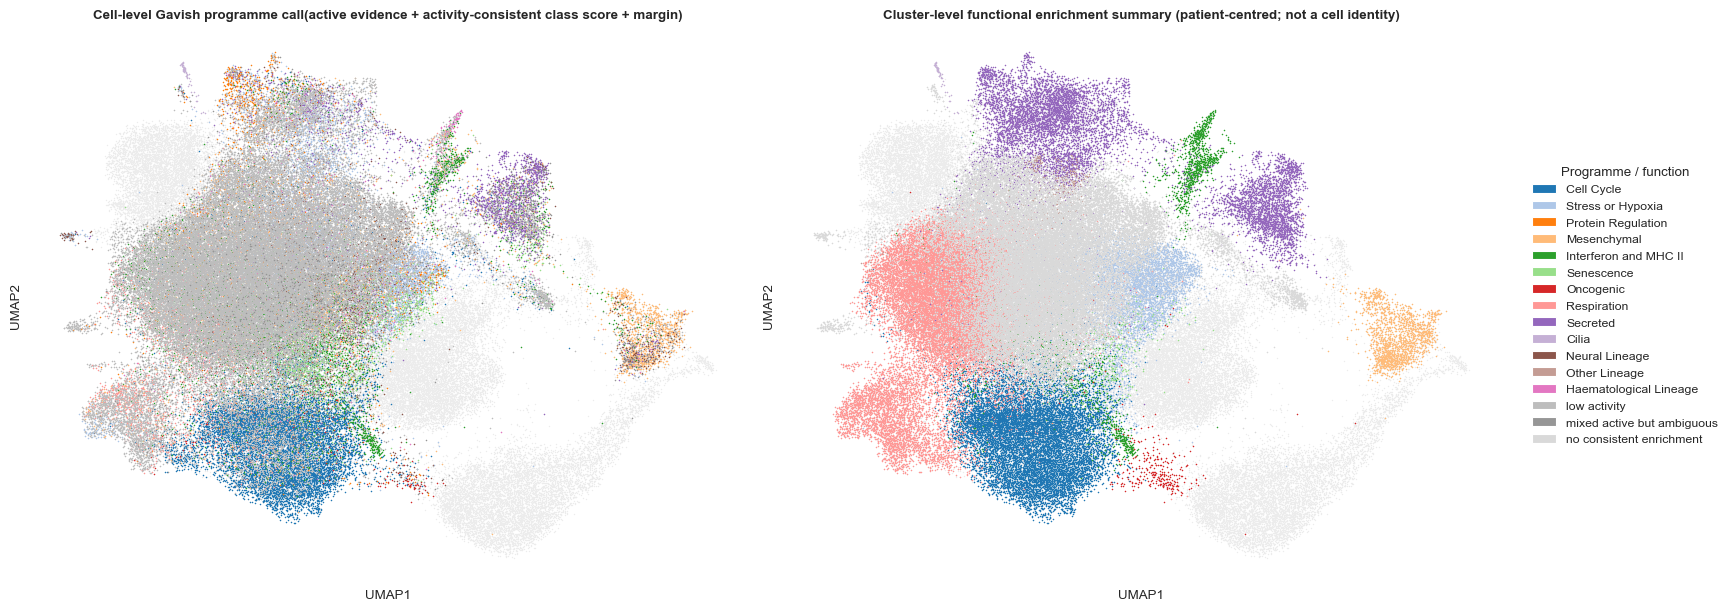

In [26]:
def categorical_umap(ax, adata, category, palette, title, background=background_colour):
    coordinates = adata.obsm["X_umap"]
    values = adata.obs[category].astype(str)

    ax.scatter(coordinates[:, 0], coordinates[:, 1], s=1.0, c=background, linewidths=0, rasterized=True)
    displayed = [value for value in palette if (values == value).any()]
    for value in displayed:
        mask = values.eq(value).to_numpy()
        ax.scatter(coordinates[mask, 0], coordinates[mask, 1], s=1.2, c=palette[value], label=value, linewidths=0, rasterized=True)

    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("UMAP1")
    ax.set_ylabel("UMAP2")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
    return displayed

fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
cell_displayed = categorical_umap(axes[0], epi, "Gavish_programme_call_revised", programme_palette, "Cell-level Gavish programme call(active evidence + activity-consistent class score + margin)")
cluster_displayed = categorical_umap(axes[1], epi, "Gavish_cluster_function_revised", programme_palette, "Cluster-level functional enrichment summary (patient-centred; not a cell identity)")

handles = [Patch(facecolor=programme_palette[value], label=value.replace("_", " "))
           for value in dict.fromkeys(cell_displayed + cluster_displayed)]
fig.legend(handles=handles, loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, title="Programme / function")
fig.savefig(fig_dir / "gavish_state_assignment_umaps_revised.png", dpi=300, bbox_inches="tight")
fig.savefig(fig_dir / "gavish_state_assignment_umaps_revised.pdf", bbox_inches="tight")
plt.show()


### Figure: state-assignment UMAPs

The left panel is the uncertainty-aware **cell-level** programme call. The right panel is a **cluster-level functional enrichment summary**, displayed on cells only for visualization. The right panel should be captioned as a cluster summary, never as a cell-state identity map.


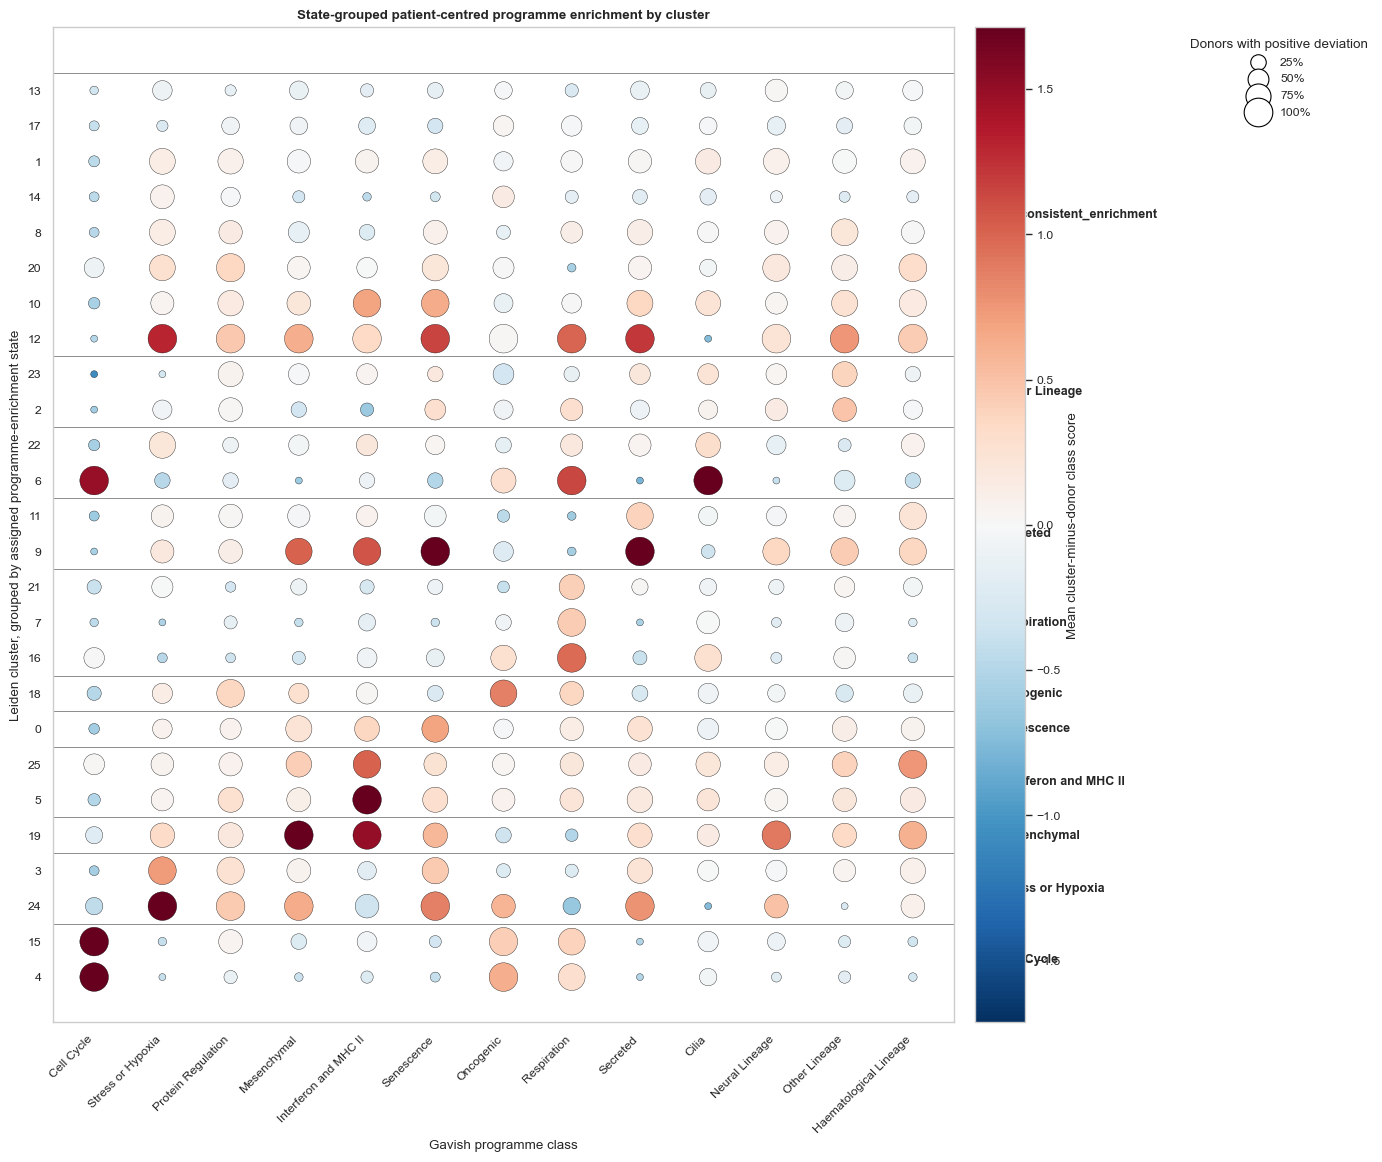

In [27]:
# State-grouped staircase bubble plot.
# One row remains one Leiden cluster; only the ordering is changed from raw cluster ID.
cluster_plot = cluster_function_table.copy()
cluster_plot = cluster_plot.merge(
    cluster_order_by_state[[cluster_key, "assigned_state", "state_rank", "cluster_strength"]],
    on=cluster_key,
    how="left",
)
cluster_plot["cluster_sort"] = cluster_plot[cluster_key].astype(str)
cluster_plot["hallmark"] = pd.Categorical(
    cluster_plot["hallmark"],
    categories=hallmark_order,
    ordered=True,
)
cluster_plot["x"] = cluster_plot["hallmark"].cat.codes
cluster_plot = cluster_plot.sort_values(
    ["state_rank", "cluster_strength", "cluster_sort"],
    ascending=[True, False, True],
)
cluster_plot["cluster_axis"] = pd.Categorical(
    cluster_plot[cluster_key].astype(str),
    categories=cluster_plot[cluster_key].astype(str).drop_duplicates().tolist(),
    ordered=True,
)
cluster_plot["y"] = pd.factorize(cluster_plot["cluster_axis"], sort=False)[0]

colour_limit = np.quantile(np.abs(cluster_plot["mean_patient_centred_deviation"]), 0.98)
colour_limit = max(float(colour_limit), 0.1)
norm = TwoSlopeNorm(vmin=-colour_limit, vcenter=0, vmax=colour_limit)

fig_height = max(5, 0.42 * cluster_plot[cluster_key].nunique() + 2)
fig, ax = plt.subplots(figsize=(14, fig_height))
points = ax.scatter(
    cluster_plot["x"],
    cluster_plot["y"],
    s=25 + 400 * cluster_plot["fraction_patients_positive"],
    c=cluster_plot["mean_patient_centred_deviation"],
    cmap="RdBu_r",
    norm=norm,
    edgecolor="black",
    linewidth=0.25,
)

# Draw state boundaries so the staircase grouping is explicit.
ordered_clusters = cluster_plot[[cluster_key, "assigned_state", "y"]].drop_duplicates()
for state, group in ordered_clusters.groupby("assigned_state", sort=False):
    y_min, y_max = group["y"].min(), group["y"].max()
    ax.axhline(y_max + 0.5, color="black", linewidth=0.7, alpha=0.45)
    ax.text(
        len(hallmark_order) + 0.25,
        (y_min + y_max) / 2,
        str(state),
        va="center",
        fontsize=9,
        fontweight="bold",
    )

ax.set_xticks(range(len(hallmark_order)), hallmark_order, rotation=45, ha="right")
ax.set_yticks(
    ordered_clusters["y"],
    [str(x) for x in ordered_clusters[cluster_key]],
)
ax.set_xlabel("Gavish programme class")
ax.set_ylabel("Leiden cluster, grouped by assigned programme-enrichment state")
ax.set_title("State-grouped patient-centred programme enrichment by cluster", fontweight="bold")
ax.grid(False)
colorbar = fig.colorbar(points, ax=ax, pad=0.02)
colorbar.set_label("Mean cluster-minus-donor class score")
size_handles = [
    ax.scatter([], [], s=25 + 400 * fraction, color="white", edgecolor="black", label=f"{fraction:.0%}")
    for fraction in [0.25, 0.50, 0.75, 1.00]
]
ax.legend(
    handles=size_handles,
    title="Donors with positive deviation",
    loc="upper left",
    bbox_to_anchor=(1.25, 1.0),
    frameon=False,
)
fig.savefig(fig_dir / "gavish_cluster_function_bubble_state_grouped_staircase.png", dpi=300, bbox_inches="tight")
fig.savefig(fig_dir / "gavish_cluster_function_bubble_state_grouped_staircase.pdf", bbox_inches="tight")
plt.show()


### Figure: patient-centred MP heatmap

Rows are all scored Gavish MPs. Columns are Leiden clusters. Each value is the mean, across donors, of the cluster MP score minus that donor's overall MP score. This preserves the complete MP-level evidence and avoids a heatmap of forced labels.


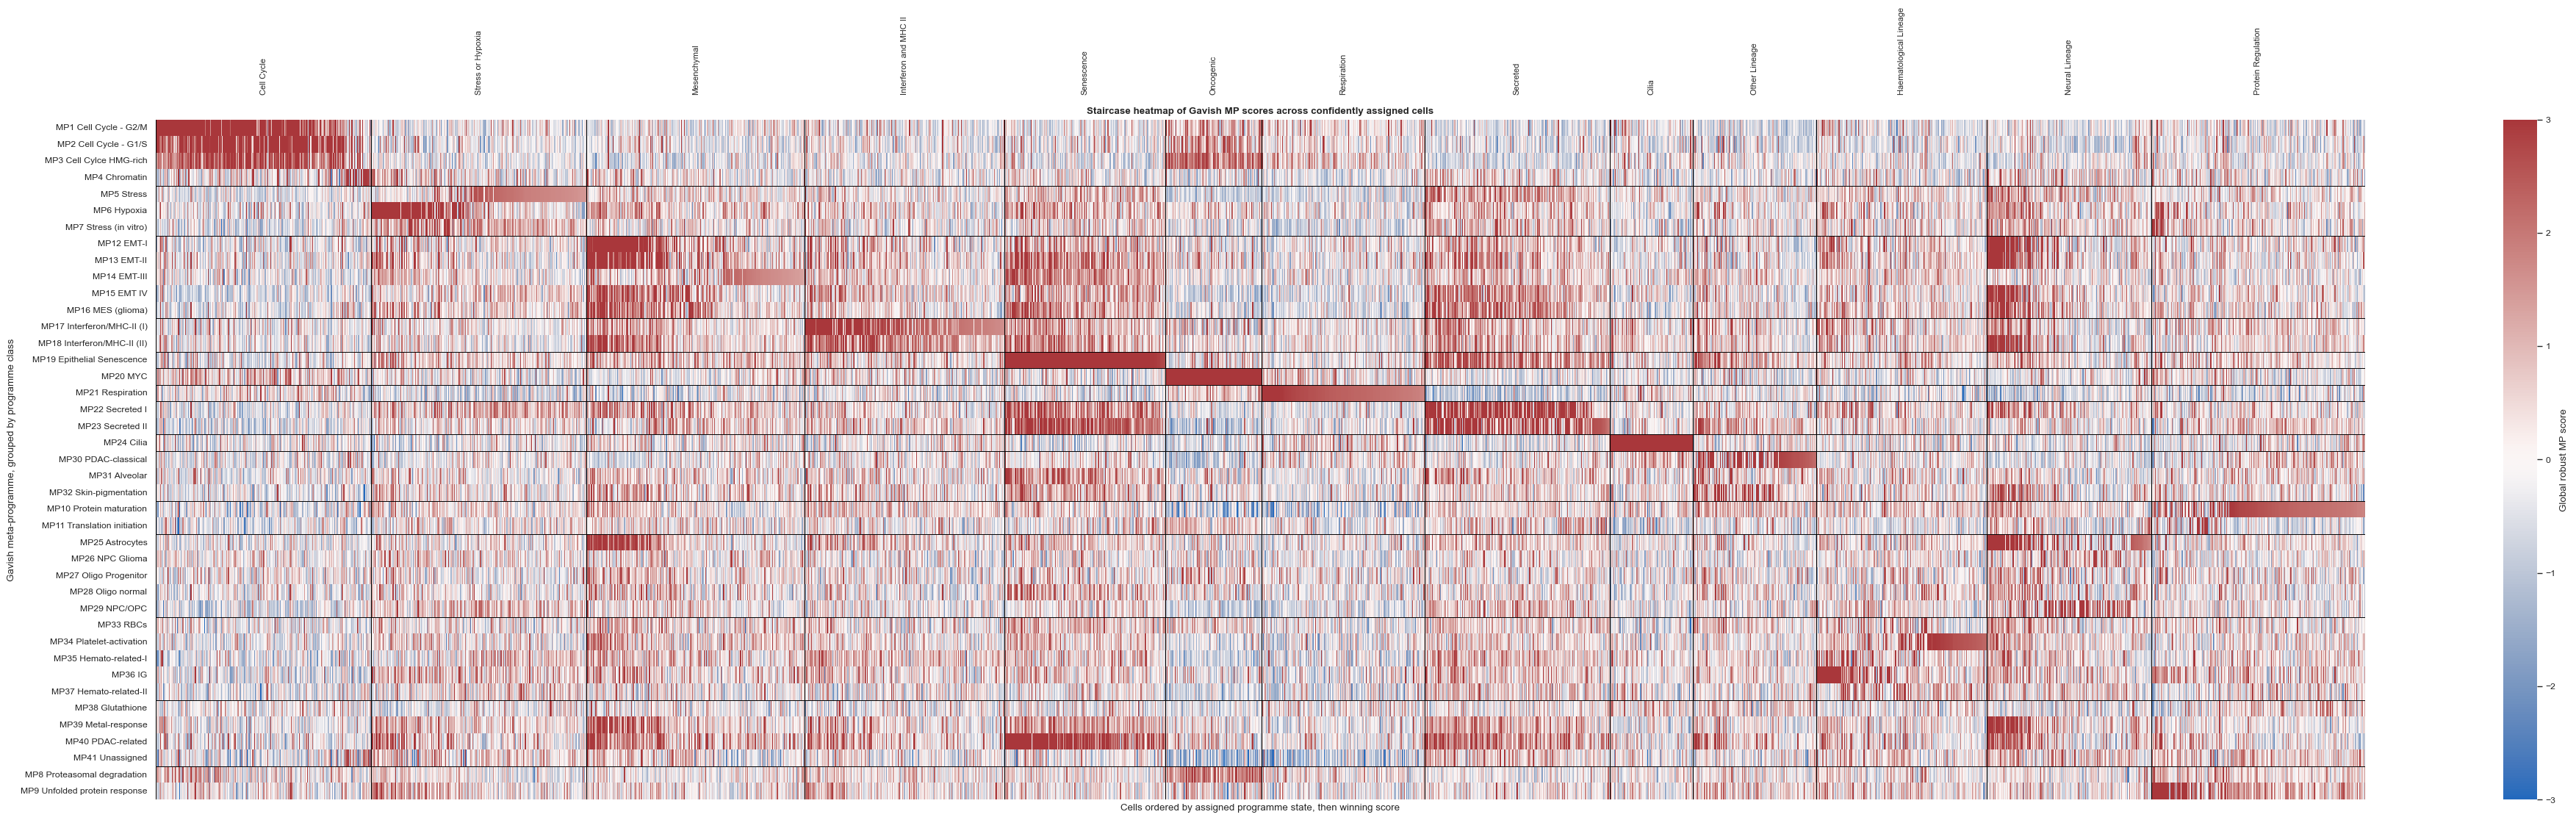

In [28]:
# Staircase MP heatmap over confidently state-assigned cells.
# To keep the figure legible, use a deterministic donor-balanced cap per state.
MAX_HEATMAP_CELLS_PER_STATE = 250
rng_heatmap = np.random.default_rng(RANDOM_SEED)

heatmap_calls = cell_assignment.loc[
    cell_assignment["assignment_status"].eq("confident_call")
].copy()
heatmap_calls["cell_id"] = heatmap_calls.index.astype(str)
heatmap_calls["assigned_state"] = heatmap_calls["programme_call"].astype(str)
heatmap_calls = heatmap_calls[heatmap_calls["assigned_state"].isin(candidate_hallmarks)]

heatmap_meta = scored_obs[[donor_key]].copy()
heatmap_meta["cell_id"] = heatmap_meta.index.astype(str)
heatmap_meta = heatmap_meta.join(heatmap_calls[["assigned_state", "top_class_score"]], how="inner")

selected_heatmap_cells = []
for state, state_frame in heatmap_meta.groupby("assigned_state", observed=True):
    donors = state_frame[donor_key].astype(str).unique().tolist()
    per_donor = max(1, MAX_HEATMAP_CELLS_PER_STATE // max(len(donors), 1))
    for donor in donors:
        donor_frame = state_frame[state_frame[donor_key].astype(str).eq(donor)]
        n_take = min(per_donor, len(donor_frame))
        selected_heatmap_cells.extend(
            rng_heatmap.choice(donor_frame.index.to_numpy(), size=n_take, replace=False).tolist()
        )

heatmap_meta = heatmap_meta.loc[sorted(set(selected_heatmap_cells))].copy()
heatmap_meta["state_rank"] = heatmap_meta["assigned_state"].map(
    {state: i for i, state in enumerate(state_order)}
)
heatmap_meta = heatmap_meta.sort_values(
    ["state_rank", "assigned_state", "top_class_score", donor_key],
    ascending=[True, True, False, True],
)

heatmap_cells = heatmap_meta.index
heatmap_values = mp_score_global_z.loc[heatmap_cells, :].T
heatmap_values.index.name = "MP"
heatmap_values.columns = heatmap_cells.astype(str)

# Order MPs by their Gavish class, then MP name. This creates a staircase where
# state blocks of columns align with the relevant programme rows.
mp_to_hallmark = {
    mp: hallmark
    for hallmark, mps in gavish_hallmarks.items()
    for mp in mps
    if mp in heatmap_values.index
}
mp_order = sorted(
    heatmap_values.index,
    key=lambda mp: (
        state_order.index(mp_to_hallmark.get(mp, "Unassigned"))
        if mp_to_hallmark.get(mp, "Unassigned") in state_order else len(state_order),
        mp,
    ),
)
heatmap_values = heatmap_values.loc[mp_order]

fig_width = max(12, 0.018 * heatmap_values.shape[1] + 4)
fig_height = max(9, 0.22 * heatmap_values.shape[0] + 3)
fig, ax = plt.subplots(figsize=(fig_width, fig_height))
sns.heatmap(
    heatmap_values,
    ax=ax,
    cmap="vlag",
    center=0,
    vmin=-3,
    vmax=3,
    xticklabels=False,
    yticklabels=True,
    cbar_kws={"label": "Global robust MP score"},
)

# State block boundaries on the cell axis.
state_boundaries = []
for state, group in heatmap_meta.groupby("assigned_state", sort=False):
    start = heatmap_meta.index.get_indexer(group.index).min()
    stop = heatmap_meta.index.get_indexer(group.index).max() + 1
    ax.axvline(start, color="black", linewidth=0.8)
    ax.text((start + stop) / 2, -1.5, state, rotation=90, ha="center", va="bottom", fontsize=8)
    state_boundaries.append((state, start, stop))
ax.axvline(heatmap_values.shape[1], color="black", linewidth=0.8)

# MP class boundaries on the row axis.
for row in range(1, len(heatmap_values)):
    prev = mp_to_hallmark.get(heatmap_values.index[row - 1], "")
    curr = mp_to_hallmark.get(heatmap_values.index[row], "")
    if prev != curr:
        ax.axhline(row, color="black", linewidth=0.7)

ax.set_title("Staircase heatmap of Gavish MP scores across confidently assigned cells", fontweight="bold")
ax.set_xlabel("Cells ordered by assigned programme state, then winning score")
ax.set_ylabel("Gavish meta-programme, grouped by programme class")
fig.savefig(fig_dir / "gavish_mp_scores_staircase_heatmap.png", dpi=300, bbox_inches="tight")
fig.savefig(fig_dir / "gavish_mp_scores_staircase_heatmap.pdf", bbox_inches="tight")
plt.show()

heatmap_meta[[donor_key, "assigned_state", "top_class_score"]].to_csv(
    df_dir / "gavish_staircase_heatmap_cell_order.csv"
)


### Figure: patient-balanced programme composition by condition

Each donor contributes one within-donor composition, regardless of how many cells or technical libraries it contributed. `low_activity` and `mixed_active_but_ambiguous` are retained as explicit uncertainty categories rather than hidden in one generic label.


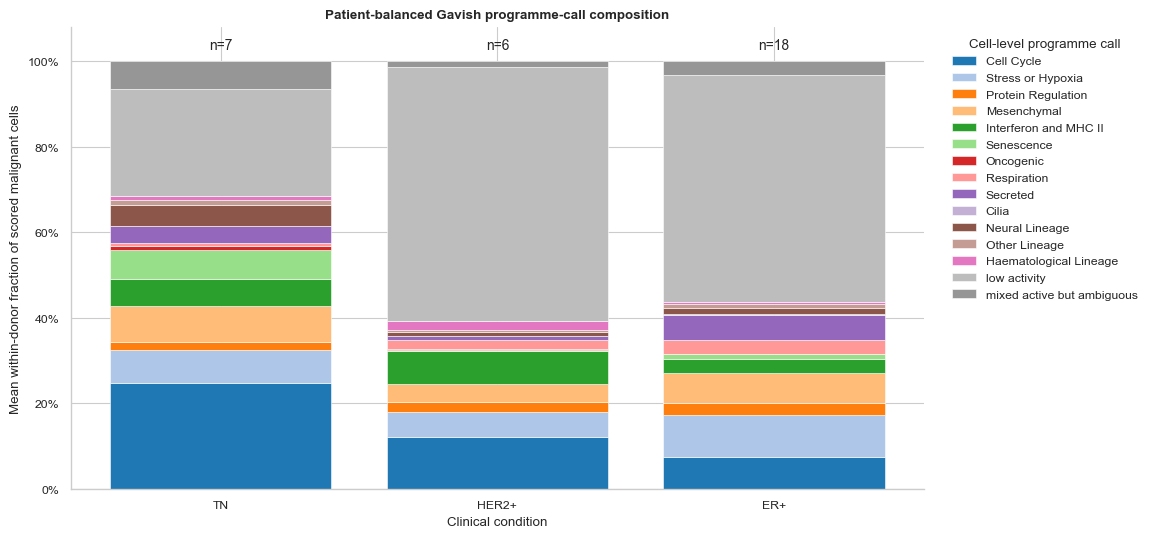

In [29]:
cell_call_frame = scored_obs[[sample_key, donor_key, condition_key]].copy()
cell_call_frame["programme_call"] = cell_assignment.loc[scored_cells, "programme_call"].astype(str)

# First calculate composition per technical sample, then take the median across
# samples for each donor. This avoids a donor with more cells/libraries dominating.
sample_call_counts = pd.crosstab(
    [cell_call_frame[sample_key], cell_call_frame[donor_key], cell_call_frame[condition_key]], cell_call_frame["programme_call"])
sample_call_fraction = sample_call_counts.div(sample_call_counts.sum(axis=1), axis=0).reset_index()

call_order = [label for label in list(class_score.columns) + ["low_activity", "mixed_active_but_ambiguous"]
              if label in sample_call_fraction.columns]
patient_call_fraction = (sample_call_fraction.groupby([donor_key, condition_key], observed=True)[call_order].median().reset_index())

condition_call_fraction = (patient_call_fraction.groupby(condition_key, observed=True)[call_order].mean())
condition_order = [condition for condition in ["TN", "HER2+", "ER+"] if condition in condition_call_fraction.index]
condition_call_fraction = condition_call_fraction.reindex(condition_order)
condition_call_fraction.to_csv(df_dir / "gavish_patient_balanced_programme_composition_by_condition.csv")
patient_call_fraction.to_csv(df_dir / "gavish_patient_programme_composition.csv", index=False)

fig, ax = plt.subplots(figsize=(11, 6))
bottom = np.zeros(len(condition_call_fraction))
for label in call_order:
    values = condition_call_fraction[label].to_numpy()
    ax.bar(condition_call_fraction.index, values, bottom=bottom,
           color=programme_palette[label], edgecolor="white", linewidth=0.4,
           label=label.replace("_", " "))
    bottom += values

n_donors = patient_call_fraction.groupby(condition_key, observed=True)[donor_key].nunique()
for position, condition in enumerate(condition_call_fraction.index):
    ax.text(position, 1.02, f"n={n_donors.loc[condition]}", ha="center", va="bottom", fontsize=10)

ax.set_ylim(0, 1.08)
ax.set_ylabel("Mean within-donor fraction of scored malignant cells")
ax.set_xlabel("Clinical condition")
ax.set_title("Patient-balanced Gavish programme-call composition", fontweight="bold")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Cell-level programme call", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
fig.savefig(fig_dir / "gavish_programme_composition_by_condition_revised.png", dpi=300, bbox_inches="tight")
fig.savefig(fig_dir / "gavish_programme_composition_by_condition_revised.pdf", bbox_inches="tight")
plt.show()


### Figure: condition composition within each programme call

This companion plot answers the reverse descriptive question: among patient-balanced programme-call composition, how is each programme distributed over conditions? It reflects the number of contributing donors per condition and is not a significance test.


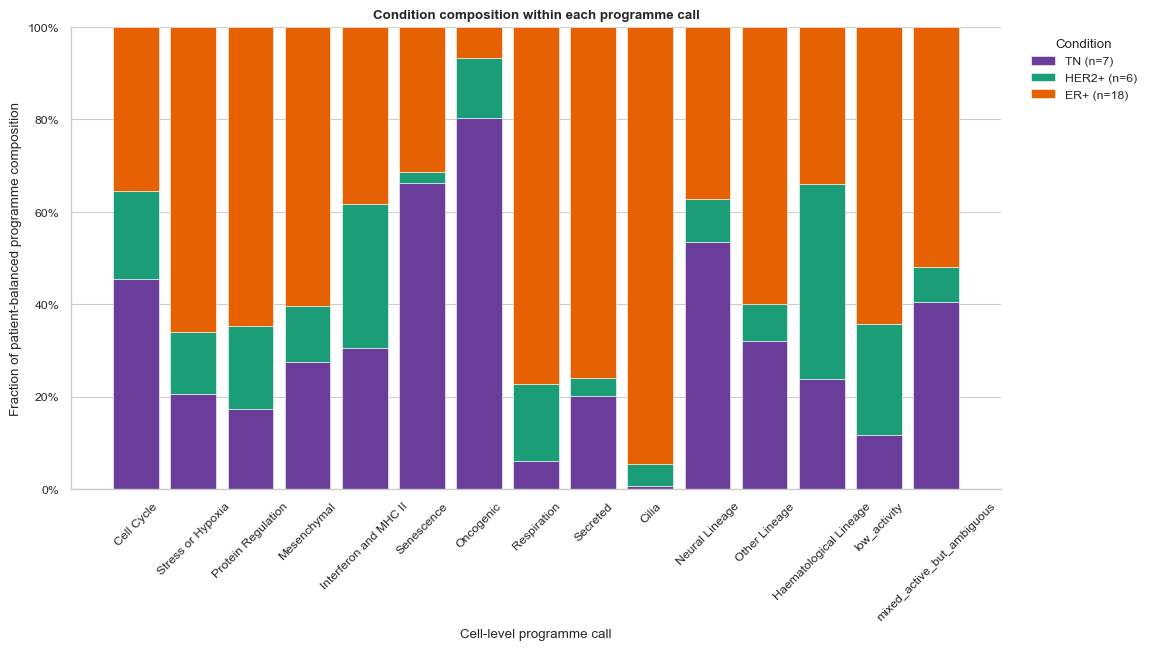

In [30]:
condition_within_call = patient_call_fraction.groupby(condition_key, observed=True)[call_order].sum().T
condition_within_call = condition_within_call.reindex(columns=condition_order).fillna(0)
condition_within_call = condition_within_call.div(condition_within_call.sum(axis=1).replace(0, np.nan), axis=0).fillna(0)
condition_within_call.to_csv(df_dir / "gavish_condition_composition_within_programme_revised.csv")

condition_palette = {"TN": "#6A3D9A", "HER2+": "#1B9E77", "ER+": "#E66101"}
fig, ax = plt.subplots(figsize=(12, 6))
bottom = np.zeros(len(condition_within_call))
for condition in condition_order:
    values = condition_within_call[condition].to_numpy()
    ax.bar(condition_within_call.index, values, bottom=bottom, color=condition_palette[condition], edgecolor="white", linewidth=0.4, label=f"{condition} (n={n_donors.loc[condition]})")
    bottom += values

ax.set_ylim(0, 1)
ax.set_ylabel("Fraction of patient-balanced programme composition")
ax.set_xlabel("Cell-level programme call")
ax.set_title("Condition composition within each programme call", fontweight="bold")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.tick_params(axis="x", rotation=45)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Condition", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
fig.savefig(fig_dir / "gavish_condition_composition_within_programme_revised.png", dpi=300, bbox_inches="tight")
fig.savefig(fig_dir / "gavish_condition_composition_within_programme_revised.pdf", bbox_inches="tight")
plt.show()


## Final reproducibility checks and reporting limitations

Before reporting any clinical association, freeze the configuration, rerun from the top, archive the output files, and verify the checks below. Condition differences are not established by a UMAP or by cell-level p-values. With the temporary donor patch, every conclusion remains conditional on later source-metadata verification.


In [31]:
assert scored_obs.groupby(condition_key, observed=True)[donor_key].nunique().get("HER2+", 0) == 6
assert set(mp_score_fixed_control.index) == set(cell_assignment.index)
assert set(mp_score_fixed_control.index) == set(ifn_qc.index)
assert cell_assignment["programme_call"].isin(
    list(candidate_hallmarks) + ["low_activity", "mixed_active_but_ambiguous"]
).all()
assert set(cluster_function_labels.index.astype(str)) == set(scored_obs[cluster_key].astype(str).unique())

print("Revised Gavish workflow completed.")
print("Key limitations:")
print("- Current malignancy definition is retained pending a separate review.")
print("- Patient IDs are temporary analysis-level identifiers parsed from sample names.")
print("- Cell calls use active-member MPs; low activity and active ambiguity remain explicit.")
print("- UMAP panels visualise programme scores; they do not prove discrete states or reference mapping.")
print("- Clinical inference must be patient-level and requires frozen metadata/covariates.")


Revised Gavish workflow completed.
Key limitations:
- Current malignancy definition is retained pending a separate review.
- Patient IDs are temporary analysis-level identifiers parsed from sample names.
- Cell calls use active-member MPs; low activity and active ambiguity remain explicit.
- UMAP panels visualise programme scores; they do not prove discrete states or reference mapping.
- Clinical inference must be patient-level and requires frozen metadata/covariates.


In [32]:
# Compact audit table for the revised activity-consistent classifier.
display(
    cell_assignment[
        [
            "assignment_status",
            "n_active_mps",
            "n_active_classes",
            "top_class",
            "best_active_class_score",
            "top_minus_second",
            "score_activity_discordance",
        ]
    ]
    .groupby("assignment_status", observed=True)
    .agg(
        n_cells=("n_active_mps", "size"),
        median_active_mps=("n_active_mps", "median"),
        median_active_classes=("n_active_classes", "median"),
        median_activity_consistent_margin=("top_minus_second", "median"),
        fraction_original_score_activity_discordance=("score_activity_discordance", "mean"),
    )
)


,n_cells,median_active_mps,median_active_classes,median_activity_consistent_margin,fraction_original_score_activity_discordance
assignment_status,,,,,
confident_call,38875,2.0,1.0,1.441462,0.268579
low_activity_all_classes,48168,0.0,0.0,NaN,0.000000
mixed_active_but_ambiguous,2334,4.0,3.0,0.125723,0.209940
